# Do counterfactual explanations carry correctness signal beyond confidence?
## Effusion — the complete result set, and what is still missing

This notebook is the single place that answers *what is actually established* for the thesis
story in `Thesis Summary.pdf`, on the **effusion** task only.

It reads **only results already on disk**. Nothing is trained here. The only quantities
computed are metrics derived from stored per-fold scores (`cv_detailed.json` carries
`y_prob` / `y_true` for every fold of every run), plus a fold reconstruction in §2 used
purely as a leakage check.

| § | Content |
|---|---|
| 0 | Provenance — which run directories this notebook trusts, and why |
| 1 | C0 and the dataset — what C2 has to detect |
| 2 | Splits and the C1 attribute space |
| 3 | The two counterfactual generators |
| 4 | **Family A** — attribute-based C2 (Δ-attributes, NN-retrieval CFs) |
| 5 | **Family B** — image-based C2 (CNN over input / CF / saliency) |
| 6 | **Family C** — diffusion-trajectory C2 (the fingerprint) |
| 7 | Where the story stands, and the gap table |
| 8 | Appendix — the same ladder on pneumothorax and RSNA |

**Kernel: `Python (thesis_env_new)`.** The repo `venv` has no `pyarrow` and cannot read the
diverse-CF parquets.

---
## §0 — Provenance

Every number below traces to one of the run directories registered here. The provenance
table is the guard: a moved or stale path fails loudly at the top of the notebook rather
than silently producing a plot of the wrong experiment.

In [ ]:
import json
import os
import sys
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.metrics import roc_auc_score, auc as _sk_auc
from sklearn.model_selection import StratifiedGroupKFold

BASE    = '/zhome/d0/a/221493/thesis'
RESULTS = '/work3/s251710/thesis_results'
DATA    = '/work3/s251710/thesis_data'
DISEASE = 'effusion'
OUT     = f'{BASE}/notebooks/images'
os.makedirs(OUT, exist_ok=True)

sys.path.insert(0, f'{BASE}/code')
from plot_config import PLOT_COLORS, PLOT_LS, PLOT_LW

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print(f'{datetime.now():%Y-%m-%d %H:%M}   disease = {DISEASE}')

2026-09-01 19:33   disease = effusion


In [ ]:
# ── The canonical run registry ────────────────────────────────────────────────
# Family A lives at a five-segment path:
#   cv_results_cf_ensemble/cf_{k}/distance_{d}/strategy_{s}/{variant}/
# The variant matters more than anything else in this notebook -- see the next cell.
_ATTR = (f'{RESULTS}/C2_custom_corrected/{DISEASE}/cv_results_cf_ensemble/'
         'cf_{k}/distance_l1/strategy_correct_cf/TEST_entropy_added(M-only)')

RUNS = {
    # Family A -- attributes x NN-retrieval counterfactuals  (CANONICAL)
    'attrA_k1':   _ATTR.format(k=1),
    'attrA_k16':  _ATTR.format(k=16),
    # Family B -- images / CNN.  ONE post-leak-fix run exists, and it is at k=16.
    'cnnB_k16':   f'{RESULTS}/C2_cnn/{DISEASE}/late/dual_sal_scalars/cf_16',
    # Family C -- diffusion-trajectory fingerprint (its own 5,431-image grid)
    'trajC':      f'{RESULTS}/diverse_cf/fingerprint_cv',
    # Superseded -- read ONCE in §4 to show why it is not used, then never again.
    'attrA_SUPERSEDED': (f'{RESULTS}/C2_custom_corrected/{DISEASE}/'
                         'cv_results_cf_ensemble/cf_1/TEST_entropy'),
}

SOURCES = {
    'c0_val':    f'{RESULTS}/C0_custom/{DISEASE}/val_c0_{DISEASE}.csv',
    'c0_train':  f'{RESULTS}/C0_custom/{DISEASE}/train_c0_{DISEASE}.csv',
    'c0_thresh': f'{RESULTS}/C0_custom/{DISEASE}/threshold.txt',
    'c2_data':   f'{RESULTS}/C2_custom/{DISEASE}/c2_data.csv',
    'grid_cfg':  f'{RESULTS}/diverse_cf/config.json',
    'cell_abl':  f'{RESULTS}/diverse_cf/cell_ablation_aucs.csv',
    'feat_spec': f'{BASE}/code/c2/c2_feature_spec.py',
}


def _stamp(p):
    if not os.path.exists(p):
        return ('MISSING', '', '')
    mt = datetime.fromtimestamp(os.path.getmtime(p))
    if os.path.isdir(p):
        return ('ok', f'{mt:%Y-%m-%d}', f'{len(os.listdir(p))} files')
    return ('ok', f'{mt:%Y-%m-%d}', f'{os.path.getsize(p) / 1e6:.1f} MB')


def _short(p):
    return p.replace(RESULTS, '$RESULTS').replace(BASE, '$BASE')


prov = pd.DataFrame(
    [{'key': k, 'kind': kind, 'status': s, 'modified': m, 'size': z, 'path': _short(p)}
     for kind, reg in [('run', RUNS), ('input', SOURCES)]
     for k, p in reg.items()
     for s, m, z in [_stamp(p)]]
)
_missing = prov[prov.status == 'MISSING']
assert _missing.empty, f'Missing inputs:\n{_missing[["key", "path"]]}'
prov

,key,kind,status,modified,size,path
0,attrA_k1,run,ok,2026-07-23,9 files,$RESULTS/C2_custom_corrected/effusion/cv_resul...
1,attrA_k16,run,ok,2026-07-17,9 files,$RESULTS/C2_custom_corrected/effusion/cv_resul...
2,cnnB_k16,run,ok,2026-07-23,38 files,$RESULTS/C2_cnn/effusion/late/dual_sal_scalars...
3,trajC,run,ok,2026-07-23,8 files,$RESULTS/diverse_cf/fingerprint_cv
4,attrA_SUPERSEDED,run,ok,2026-07-17,8 files,$RESULTS/C2_custom_corrected/effusion/cv_resul...
5,c0_val,input,ok,2026-07-14,1099.5 MB,$RESULTS/C0_custom/effusion/val_c0_effusion.csv
6,c0_train,input,ok,2026-07-14,1075.9 MB,$RESULTS/C0_custom/effusion/train_c0_effusion.csv
7,c0_thresh,input,ok,2026-05-12,0.0 MB,$RESULTS/C0_custom/effusion/threshold.txt
8,c2_data,input,ok,2026-07-16,1094.3 MB,$RESULTS/C2_custom/effusion/c2_data.csv
9,grid_cfg,input,ok,2026-07-17,0.0 MB,$RESULTS/diverse_cf/config.json


### Which Family-A run is canonical, and why the choice matters

Two post-leak-fix Family-A trees exist and they **disagree on the MSP baseline**:

| directory | B1 = MSP (LR / RF / MLP) | B3, B5 present? |
|---|---|---|
| `cf_{k}/TEST_entropy/` | 0.8360 / 0.7182 / 0.8360 | ✗ |
| `cf_{k}/distance_l1/strategy_correct_cf/TEST_entropy_added(M-only)/` | 0.7362 / 0.7502 / **0.8501** | ✓ |

`TEST_entropy/` was written by an older code revision that **swapped** the binary entropy
H(p) into *every* design matrix, baselines included — so its "B1" is H(p), not p, and a
linear reader scores 0.8360 on it. The current pipeline
(`c2_cv_pipeline_cf_ensemble.py`, docstring section "Entropy mode") *adds* H(p) to the
M/MCF configs only and leaves B1–B5 untouched, which is the correct construction for a
reference baseline.

`TEST_entropy/` also **omits B3 and B5** — the two embedding baselines. Without them the
embedding-consuming models (M4, M5, MCF4, MCF5) have no honest comparator, and an
embedding gain cannot be told apart from a counterfactual gain.

**This notebook uses `TEST_entropy_added(M-only)` throughout.** The consequence is a much
smaller headline: the counterfactual gain over a well-fit MSP drops from a nominal +0.017
to **+0.004**. §4.0 shows the two side by side, once.

In [ ]:
# ── Plot style ────────────────────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-white')
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 12,
    'axes.titlesize': 13, 'axes.labelsize': 12,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 1.1, 'grid.alpha': 0.3, 'grid.linewidth': 0.6,
    'figure.dpi': 110, 'savefig.dpi': 220, 'savefig.bbox': 'tight',
})

MODELS       = ['LR', 'RF', 'MLP']
MODEL_NAMES  = {'LR': 'Logistic Regression', 'RF': 'Random Forest', 'MLP': 'MLP'}
CONFIG_ORDER = ['B1', 'B2', 'B3', 'B4', 'B5',
                'M1', 'M2', 'M3', 'M4', 'M5', 'M6',
                'MCF1', 'MCF2', 'MCF3', 'MCF4', 'MCF5']

# What each config contains (c2_cv_pipeline_cf_ensemble.py module docstring).
CONFIG_DESC = {
    'B1': 'prob',                       'B2': 'attr',
    'B3': 'emb',                        'B4': 'prob + attr',
    'B5': 'prob + emb',
    'M1': 'delta',                      'M2': 'prob + delta',
    'M3': 'prob + delta + attr',        'M4': 'prob + delta + emb',
    'M5': 'prob + delta + attr + emb',  'M6': 'prob + delta + attr + cf_prob',
    'MCF1': 'prob + cf_prob',
    'MCF2': 'prob + cf_prob + attr + cf_attr',
    'MCF3': 'MCF2 + delta',
    'MCF4': 'MCF3 + emb + cf_emb',
    'MCF5': 'MCF4 + delta_emb',
}
# Configs that see NO counterfactual-derived feature at all -- the controls.
NO_CF_CONFIGS = ['B1', 'B2', 'B3', 'B4', 'B5']
print(f'{len(CONFIG_ORDER)} configs, '
      f'{len(NO_CF_CONFIGS)} of them counterfactual-free controls')

16 configs, 5 of them counterfactual-free controls


In [ ]:
# ── Loaders + metric helpers ──────────────────────────────────────────────────
# Consolidated from ROC_tabular.ipynb, ROC_cnn.ipynb and ROC_diffusion_dynamics.ipynb,
# where these were maintained in triplicate.
COMMON_FPR = np.linspace(0, 1, 300)


def load_summary(run):
    return pd.read_csv(os.path.join(RUNS[run], 'cv_summary.csv'))


def load_detailed(run):
    with open(os.path.join(RUNS[run], 'cv_detailed.json')) as fh:
        return json.load(fh)


def summarise(folds):
    # Mean ROC + AUC across CV folds, interpolated onto a common FPR grid.
    tprs = [np.interp(COMMON_FPR, f['fpr'], f['tpr']) for f in folds]
    aucs = np.array([f['auc'] for f in folds])
    return {'fpr': COMMON_FPR, 'tpr': np.mean(tprs, axis=0), 'std': np.std(tprs, axis=0),
            'auc': aucs.mean(), 'auc_std': aucs.std(), 'aucs': aucs, 'n_folds': len(folds)}


def pooled_oof(folds):
    # Concatenate held-out scores across folds -> one prediction per image.
    # Each image is in exactly one test fold, so this is a single out-of-fold vector.
    # It is what lets DeLong run on n = 44k instead of on 5 fold-level AUCs (4 dof,
    # almost no power at these effect sizes). It is a different estimand from the mean
    # fold AUC -- it mixes folds that may be calibrated differently -- so both are
    # always reported side by side.
    y = np.concatenate([np.asarray(f['y_true'], dtype=int) for f in folds])
    p = np.concatenate([np.asarray(f['y_prob'], dtype=float) for f in folds])
    return y, p


def risk_coverage(scores, correct):
    # Sort by descending C2 score; risk = C0 error rate on the accepted prefix.
    # Same construction as compute_risk_coverage() in
    # code/c2/c2_cv_rejection_analysis_new_split.py. Returns (coverage, risk, AURC).
    scores, correct = np.asarray(scores, float), np.asarray(correct, int)
    order = np.argsort(scores)[::-1]
    k = np.arange(1, len(scores) + 1)
    risk = np.cumsum(1 - correct[order]) / k
    coverage = k / len(scores)
    return coverage, risk, _sk_auc(coverage, risk)


print('helpers ready')

helpers ready


In [ ]:
# ── Fast DeLong (Sun & Xu, 2014) ──────────────────────────────────────────────
# Two correlated AUCs on the SAME samples. Used instead of a paired t-test over 5 fold
# AUCs, which has 4 degrees of freedom and almost no power at the effect sizes here.
def _midrank(x):
    order = np.argsort(x)
    z, n = x[order], len(x)
    t = np.zeros(n, dtype=float)
    i = 0
    while i < n:
        j = i
        while j < n and z[j] == z[i]:
            j += 1
        t[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    out = np.empty(n, dtype=float)
    out[order] = t
    return out


def _fast_delong(preds, m):
    k, n = preds.shape
    nn = n - m
    pos, neg = preds[:, :m], preds[:, m:]
    tx = np.vstack([_midrank(pos[r]) for r in range(k)])
    ty = np.vstack([_midrank(neg[r]) for r in range(k)])
    tz = np.vstack([_midrank(preds[r]) for r in range(k)])
    auc = tz[:, :m].sum(axis=1) / m / nn - (m + 1.0) / 2.0 / nn
    v01 = (tz[:, :m] - tx) / nn
    v10 = 1.0 - (tz[:, m:] - ty) / m
    return auc, np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / nn


def delong_test(y_true, s1, s2):
    # (auc1, auc2, two-sided p) for H0: AUC(s1) == AUC(s2) on the SAME samples.
    y = np.asarray(y_true, dtype=int)
    order = np.argsort(-y, kind='mergesort')          # positives first, order preserved
    m = int(y.sum())
    preds = np.vstack([np.asarray(s1, float), np.asarray(s2, float)])[:, order]
    auc, cov = _fast_delong(preds, m)
    c = np.array([[1.0, -1.0]])
    var = float(np.asarray(c @ cov @ c.T).ravel()[0])
    if var <= 0:
        return float(auc[0]), float(auc[1]), 1.0
    z = (auc[0] - auc[1]) / np.sqrt(var)
    return float(auc[0]), float(auc[1]), float(2 * stats.norm.sf(abs(z)))


_rng = np.random.default_rng(0)
_y = _rng.integers(0, 2, 400)
_s = _rng.normal(_y * 0.8, 1.0)
_a1, _a2, _p = delong_test(_y, _s, _s)
assert abs(_a1 - _a2) < 1e-12 and _p > 0.999
assert abs(_a1 - roc_auc_score(_y, _s)) < 1e-9, 'DeLong AUC disagrees with sklearn'
print(f'DeLong self-test OK  (auc {_a1:.4f} matches sklearn, p={_p:.3f})')

DeLong self-test OK  (auc 0.7443 matches sklearn, p=1.000)


In [ ]:
# ── Integrity check: do the stored score vectors reproduce the stored AUCs? ───
# Every metric in this notebook is recomputed from cv_detailed.json's y_prob / y_true.
# If those arrays did not reproduce each run's own reported fold AUC, every downstream
# risk-coverage curve and DeLong test would be reading the wrong thing.
def _check(name, folds):
    diffs = [abs(roc_auc_score(f['y_true'], f['y_prob']) - f['auc']) for f in folds]
    return {'run': name, 'folds': len(folds), 'max |recomputed − stored|': max(diffs)}


_a = load_detailed('attrA_k1')
_c = load_detailed('trajC')
with open(os.path.join(RUNS['cnnB_k16'], 'cv_detailed.json')) as fh:
    _b = json.load(fh)

integrity = pd.DataFrame([
    _check('Family A — attrA_k1  MLP/B1', _a['MLP']['B1']),
    _check('Family A — attrA_k1  RF/MCF5', _a['RF']['MCF5']),
    _check('Family B — cnnB_k16', _b),
    _check('Family C — trajC  RF/fingerprint', _c['RF']['fingerprint']),
])
assert integrity['max |recomputed − stored|'].max() < 1e-6, integrity
print('stored y_prob / y_true reproduce every stored fold AUC to <1e-6\n')
integrity

stored y_prob / y_true reproduce every stored fold AUC to <1e-6



,run,folds,max |recomputed − stored|
0,Family A — attrA_k1 MLP/B1,5,0.0
1,Family A — attrA_k1 RF/MCF5,5,0.0
2,Family B — cnnB_k16,5,0.0
3,Family C — trajC RF/fingerprint,5,0.0


---
## §1 — C0 and the dataset

**C0** is a DenseNet121 fine-tuned on CheXpert v1.0-small (224×224) for binary
**Pleural Effusion**, trained on a patient-level stratified split
(`code/c0/c0_custom_split.py`). It is frozen: this project never retrains or modifies it.

The operating threshold is not 0.5 — it was tuned once on the training split and stored in
`threshold.txt`. Every `correct` label downstream is defined against *that* threshold.

The two large CSVs read here are ~1.1 GB each, so the slim projections are cached to
`notebooks/.cache/` on first run.

In [ ]:
# ── Cached slim reads of the two 1.1 GB CSVs ──────────────────────────────────
CACHE = f'{BASE}/notebooks/.cache'
os.makedirs(CACHE, exist_ok=True)


def slim_read(src_path, cols, tag):
    """Read only `cols` from a large CSV, caching the projection as parquet."""
    cache_f = f'{CACHE}/{tag}.parquet'
    if os.path.exists(cache_f):
        return pd.read_parquet(cache_f)
    df = pd.read_csv(src_path, usecols=cols)
    df.to_parquet(cache_f, index=False)
    return df


C0_THRESH = float(open(SOURCES['c0_thresh']).read().strip())

c0_val   = slim_read(SOURCES['c0_val'],   ['prob', 'true'], 'c0_val_slim')
c0_train = slim_read(SOURCES['c0_train'], ['prob', 'true'], 'c0_train_slim')
print(f'C0 operating threshold = {C0_THRESH}   '
      f'(train {len(c0_train):,} / held-out val {len(c0_val):,})')

C0 operating threshold = 0.5634   (train 60,141 / held-out val 61,442)


In [ ]:
# ── C0 performance on its held-out set ────────────────────────────────────────
def c0_row(df, name):
    pred = (df['prob'] >= C0_THRESH).astype(int)
    return {
        'split': name,
        'n images': f'{len(df):,}',
        'prevalence': f'{df["true"].mean():.3f}',
        'AUROC': f'{roc_auc_score(df["true"], df["prob"]):.4f}',
        'accuracy @ thr': f'{(pred == df["true"]).mean():.4f}',
        'ERROR RATE': f'{(pred != df["true"]).mean():.4f}',
    }


c0_table = pd.DataFrame([c0_row(c0_train, 'C0 train'), c0_row(c0_val, 'C0 held-out val')])
print(f'threshold = {C0_THRESH}  (tuned on train, NOT 0.5)\n')
c0_table

threshold = 0.5634  (tuned on train, NOT 0.5)



,split,n images,prevalence,AUROC,accuracy @ thr,ERROR RATE
0,C0 train,"60,141",0.704,0.9729,0.9248,0.0752
1,C0 held-out val,"61,442",0.714,0.9566,0.9109,0.0891


The held-out error rate is the number that governs everything downstream: **C2's positive
class (an incorrect C0 prediction) is a ~9 % minority**. Detecting an event that rare is
itself a constraint on the evaluation, independent of any method — this is the point made
in the *Impact* section of the proposal about curating datasets with controlled error
rates.

In [ ]:
# ── The C2 cohort: C0's held-out set, restricted to images C1 could segment ───
c2 = slim_read(SOURCES['c2_data'],
               ['path', 'prob', 'pred', 'true', 'correct', 'patient_id'], 'c2_slim')

cohort = pd.DataFrame([
    {'stage': 'C0 held-out val',              'images': len(c0_val),   'patients': None},
    {'stage': 'C2 cohort (C1 attrs present)', 'images': len(c2),
     'patients': c2['patient_id'].nunique()},
])
cohort['images'] = cohort['images'].map('{:,}'.format)
cohort['patients'] = cohort['patients'].map(lambda v: '' if pd.isna(v) else f'{int(v):,}')

n_err = int((1 - c2['correct']).sum())
print(f'C2 target      : correct = 1 if C0 was right at thr {C0_THRESH}')
print(f'C2 class balance: {c2["correct"].mean():.4f} correct  /  '
      f'{n_err:,} errors to detect ({1 - c2["correct"].mean():.2%})')
print(f'attribute-extraction loss: {len(c0_val) - len(c2):,} images '
      f'({1 - len(c2) / len(c0_val):.1%}) had no usable C1 segmentation\n')
cohort

C2 target      : correct = 1 if C0 was right at thr 0.5634
C2 class balance: 0.9173 correct  /  3,734 errors to detect (8.27%)
attribute-extraction loss: 16,287 images (26.5%) had no usable C1 segmentation



,stage,images,patients
0,C0 held-out val,"61,442",
1,C2 cohort (C1 attrs present),"45,155","15,912"


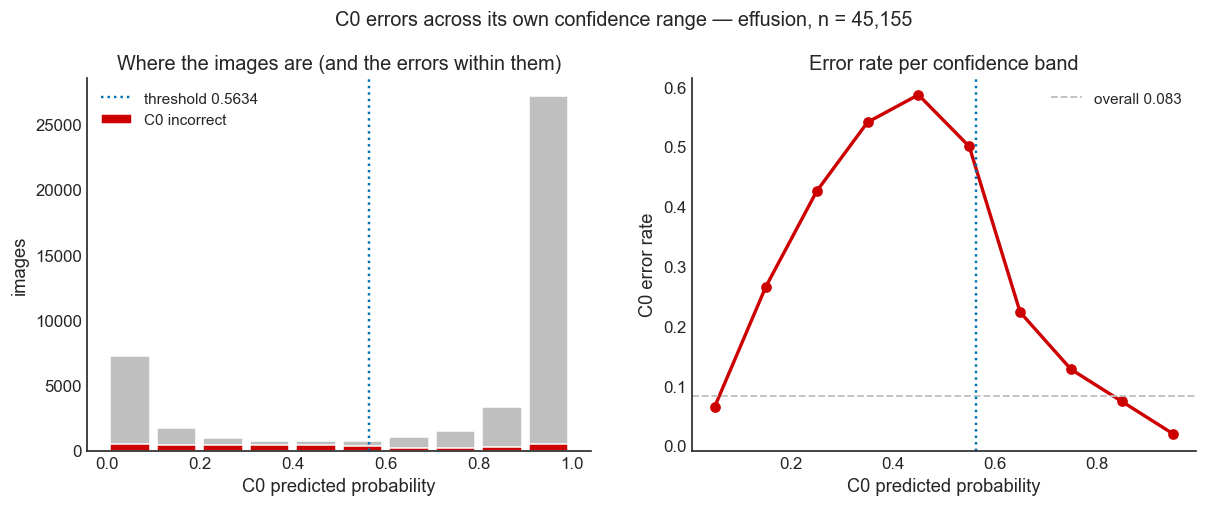

,images,errors,error rate
band,,,
"(-0.001, 0.1]",7235,469,0.0648
"(0.1, 0.2]",1710,454,0.2655
"(0.2, 0.3]",936,398,0.4252
"(0.3, 0.4]",764,413,0.5406
"(0.4, 0.5]",723,424,0.5864
"(0.5, 0.6]",750,375,0.5000
"(0.6, 0.7]",1014,226,0.2229
"(0.7, 0.8]",1516,193,0.1273
"(0.8, 0.9]",3331,245,0.0736


In [ ]:
# ── Where C0's errors sit on its own confidence axis ──────────────────────────
# This is the picture every rejection function has to improve on: errors concentrate in
# the uncertain band, which is exactly why MSP is such a strong baseline.
bins   = np.linspace(0, 1, 11)
c2b    = c2.assign(band=pd.cut(c2['prob'], bins, include_lowest=True))
grp    = c2b.groupby('band', observed=True)
n_tot  = grp.size()
n_err_b = grp['correct'].apply(lambda s: int((1 - s).sum()))
err_rate = n_err_b / n_tot

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
centres = np.array([iv.mid for iv in n_tot.index])

axes[0].bar(centres, n_tot.values, width=0.085, color='#BFBFBF', edgecolor='white')
axes[0].bar(centres, n_err_b.values, width=0.085, color='#CC0000', edgecolor='white',
            label='C0 incorrect')
axes[0].set(xlabel='C0 predicted probability', ylabel='images',
            title='Where the images are (and the errors within them)')
axes[0].axvline(C0_THRESH, color='#0072B2', ls=':', lw=1.6,
                label=f'threshold {C0_THRESH}')
axes[0].legend(frameon=False)

axes[1].plot(centres, err_rate.values, 'o-', color='#CC0000', lw=2.2)
axes[1].axhline(1 - c2['correct'].mean(), color='#BFBFBF', ls='--', lw=1.2,
                label=f'overall {1 - c2["correct"].mean():.3f}')
axes[1].axvline(C0_THRESH, color='#0072B2', ls=':', lw=1.6)
axes[1].set(xlabel='C0 predicted probability', ylabel='C0 error rate',
            title='Error rate per confidence band')
axes[1].legend(frameon=False)

fig.suptitle(f'C0 errors across its own confidence range — {DISEASE}, n = {len(c2):,}',
             y=1.02, fontsize=13)
fig.savefig(f'{OUT}/story_c0_errors_by_band_{DISEASE}.png')
plt.show()

pd.DataFrame({'images': n_tot, 'errors': n_err_b, 'error rate': err_rate.round(4)})

---
## §2 — Splits and the C1 attribute space

**The split hierarchy.** C0 is trained on its own patient-level split; C2 is then
cross-validated *inside C0's held-out set*, so no image C2 ever sees was used to fit C0.

Within that held-out set, C2 uses 5-fold `StratifiedGroupKFold` **grouped on
`patient_id`**. This matters: CheXpert patients contribute several studies, and an
image-level split leaks a patient's other images across the train/test boundary. That
leak was present until 2026-07-16 and inflated every C2 result predating it — which is
why this notebook only reads post-fix directories.

The cell below reconstructs the folds from the pipeline's own parameters and checks two
things: that no patient crosses a fold boundary, and that the reconstructed fold sizes
match the fold sizes actually stored in the canonical run's `cv_detailed.json`.

In [ ]:
# ── Reproduce the pipeline's folds and verify them ────────────────────────────
# Parameters copied from c2_cv_pipeline_cf_ensemble.py: N_FOLDS=5, RANDOM_SEED=42,
# StratifiedGroupKFold(shuffle=True), groups = patient_id, stratify on `correct`.
skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
y_c2, g_c2 = c2['correct'].values, c2['patient_id'].values

fold_rows, overlaps = [], []
for i, (tr, te) in enumerate(skf.split(c2, y_c2, groups=g_c2)):
    shared = set(g_c2[tr]) & set(g_c2[te])
    overlaps.append(len(shared))
    fold_rows.append({
        'fold': i, 'train n': len(tr), 'test n': len(te),
        'test patients': len(set(g_c2[te])),
        'test correct rate': round(float(y_c2[te].mean()), 4),
        'shared patients': len(shared),
    })

folds_df = pd.DataFrame(fold_rows)
assert max(overlaps) == 0, f'PATIENT LEAK: {overlaps}'

# Cross-check against the fold sizes stored in the canonical run.
_det = load_detailed('attrA_k1')
stored_sizes = [len(f['y_true']) for f in _det['LR']['B1']]
folds_df['stored test n'] = stored_sizes
folds_df['match'] = np.where(folds_df['test n'] == folds_df['stored test n'], 'yes', 'NO')

print(f'patient overlap train/test, all folds: {overlaps}  -> no leak')
print(f'reconstructed vs stored fold sizes  : '
      f'{"identical" if (folds_df["match"] == "yes").all() else "DIVERGENT"}\n')
folds_df

patient overlap train/test, all folds: [0, 0, 0, 0, 0]  -> no leak
reconstructed vs stored fold sizes  : identical



,fold,train n,test n,test patients,test correct rate,shared patients,stored test n,match
0,0,36339,8816,3207,0.9149,0,8816,yes
1,1,36525,8630,3179,0.9163,0,8630,yes
2,2,36068,9087,3175,0.9193,0,9087,yes
3,3,35961,9194,3164,0.9195,0,9194,yes
4,4,35727,9428,3187,0.9163,0,9428,yes


In [ ]:
# ── The C1 attribute space, by anatomical region and feature family ───────────
# c2_data.csv columns are built by subtraction: everything that is not meta and not emb_*
# is an attribute. The taxonomy below re-derives that grouping from the header alone.
header = pd.read_csv(SOURCES['c2_data'], nrows=0).columns.tolist()

sys.path.insert(0, f'{BASE}/code/c2')
from c2_feature_spec import C0_DERIVED_COLS

META = {'path', 'prob', 'true', 'pred', 'correct', 'cam_path', 'patient_id',
        *C0_DERIVED_COLS}
emb_cols  = [c for c in header if c.startswith('emb_')]
attr_cols = [c for c in header if c not in META and not c.startswith('emb_')]

GEOM_SUFFIX = ('_area_pixels', '_bbox_width', '_bbox_height', '_bbox_ratio', '_perimeter')


def classify(col):
    if '_original_shape2D_' in col:
        return col.split('_original_shape2D_')[0], 'shape2D (radiomic)'
    if '_original_firstorder_' in col:
        return col.split('_original_firstorder_')[0], 'firstorder (radiomic)'
    for s in GEOM_SUFFIX:
        if col.endswith(s):
            return col[: -len(s)], 'geometry'
    if col.startswith(('age_', 'sex_', 'race_')):
        return '(patient)', 'demographic'
    return '(derived)', 'clinical ratio'


tax = pd.DataFrame([classify(c) for c in attr_cols], columns=['region', 'family'])
pivot = (tax.pivot_table(index='region', columns='family', aggfunc=len, fill_value=0)
            .assign(total=lambda d: d.sum(axis=1))
            .sort_values('total', ascending=False))

print(f'c2_data.csv: {len(header):,} columns')
print(f'  {len(emb_cols):>5,}  emb_*        C0 penultimate embedding')
print(f'  {len(attr_cols):>5,}  attributes   the C1 space (feeds attr / cf_attr / delta)')
print(f'  {len(META):>5,}  meta         excluded, incl. {len(C0_DERIVED_COLS)} C0-derived')
print(f'\n{len(tax["region"].unique()) - 2} anatomical regions x '
      f'{tax["family"].nunique()} feature families\n')
pivot

c2_data.csv: 1,493 columns
  1,024  emb_*        C0 penultimate embedding
    454  attributes   the C1 space (feeds attr / cf_attr / delta)
     15  meta         excluded, incl. 8 C0-derived

13 anatomical regions x 4 feature families



family,demographic,firstorder (radiomic),geometry,shape2D (radiomic),total
region,,,,,
Aorta,0,18,5,9,32
Facies Diaphragmatica,0,18,5,9,32
Heart,0,18,5,9,32
Left Hilus Pulmonis,0,18,5,9,32
Left Clavicle,0,18,5,9,32
Left Lung,0,18,5,9,32
Left Scapula,0,18,5,9,32
Right Lung,0,18,5,9,32
Mediastinum,0,18,5,9,32


**Why `margin` and `prob_*` are excluded.** `code/c2/c2_feature_spec.py` is the single
source of truth for what counts as C0-derived rather than image-derived:

- `margin` = |p − threshold|, correlation 1.0000 with C0 confidence; alone it predicts
  `correct` at AUROC 0.731.
- the seven `prob_*` SDN internal-classifier taps; `prob_denseblock4` alone reaches 0.737.

Both were silently landing in the attribute space (8 of 469 columns) before the fix. With
them present, B1 — the "no counterfactual, no embedding" anchor — was quietly receiving a
0.73-AUROC confidence feature, which compresses the measured gap between the baselines and
the Δ-attribute models. C0-derived signal is not forbidden here; it is *opt-in*, entering
only through the explicitly named `prob` / `cf_prob` blocks so its contribution is measured
rather than assumed.

---
## §3 — The two counterfactual generators

Both generators answer the same question — *what would have to change for C0 to flip?* —
under opposite assumptions about what a counterfactual should be.

**Nearest-opposite-neighbour retrieval** (`c2_cv_pipeline_cf_ensemble.py`). The
counterfactual is a *real* image from the training fold: the nearest training example
that C0 classified as the opposite class **and got right** (the `correct_cf` routing rule,
so the CF is never itself an error):

- `pred = 1` (TP or FP) → nearest TN
- `pred = 0` (TN or FN) → nearest TP

Retrieval is exact and cheap, and every query has a counterfactual. But it is, by
construction, a *distance to the decision boundary* — which is the redundancy with
confidence flagged in the proposal's *Future work*.

**Classifier-guided diffusion** (`cf_generate_diverse_counterfactuals.py`). The
counterfactual is *generated* by running guided reverse diffusion on the query itself,
once per (region × t_start) cell of a grid. Each query gets its own counterfactuals, and
the region mask forces the edit into a chosen anatomy — including `Spine`, which acts as
the control region since spine changes should not flip an effusion call.

In [ ]:
# ── What each generator actually produced ─────────────────────────────────────
grid_cfg = json.load(open(SOURCES['grid_cfg']))

gen = pd.DataFrame([
    {'generator': 'NN-opposite-neighbour retrieval',
     'counterfactual is': 'a real training image',
     'per query': 'k nearest (k = 1 and 16 on disk)',
     'coverage': f'{len(c2):,} images (whole C2 cohort)',
     'used by': 'Family A (§4), Family B (§5)'},
    {'generator': 'classifier-guided diffusion (grid)',
     'counterfactual is': 'a generated edit of the query itself',
     'per query': f'{len(grid_cfg["conditions"])} conditions x '
                  f'{len(grid_cfg["t_start_values"])} t_start = '
                  f'{len(grid_cfg["conditions"]) * len(grid_cfg["t_start_values"])} cells',
     'coverage': '5,431 images (sub-grid)',
     'used by': 'Family C (§6)'},
])

print('diverse-CF grid config:')
print(f'  conditions   : {grid_cfg["conditions"]}')
print(f'  t_start      : {grid_cfg["t_start_values"]}   guidance w = '
      f'{grid_cfg["guidance_weight"]}')
print(f'  control region: {grid_cfg["control_region"]}   '
      f'n per cell = {grid_cfg["n_per_cell"]}')
print(f'  source       : {os.path.basename(grid_cfg["source_csv"])}  '
      f'(threshold {grid_cfg["threshold"]})\n')
gen

diverse-CF grid config:
  conditions   : ['general', 'Facies Diaphragmatica', 'Left Lung', 'Right Lung', 'Spine']
  t_start      : [5, 10, 20]   guidance w = 0.05
  control region: Spine   n per cell = 1000
  source       : c2_data.csv  (threshold 0.5634)



,generator,counterfactual is,per query,coverage,used by
0,NN-opposite-neighbour retrieval,a real training image,k nearest (k = 1 and 16 on disk),"45,155 images (whole C2 cohort)","Family A (§4), Family B (§5)"
1,classifier-guided diffusion (grid),a generated edit of the query itself,5 conditions x 3 t_start = 15 cells,"5,431 images (sub-grid)",Family C (§6)


> **The coverage asymmetry is the single most important caveat in this notebook.**
> Families A and B are evaluated on **45,155 images**; Family C is evaluated on a
> **5,431-image sub-grid**. Their AUROCs are *not* directly comparable, and §6 therefore
> rebuilds the confidence baseline inside the grid rather than importing B1 from §4.

---
## §4 — Family A: attribute-based C2

> *Assumption:* the correctness signal lives in **which** semantic properties change
> between an image and its counterfactual, and **by how much**.

C1 extracts the attribute vector for the query and for its counterfactual; the difference
is the **Δ-attribute vector**. The ablation ladder adds one source at a time, so each step
isolates that source's contribution:

| block | configs |
|---|---|
| controls — no counterfactual at all | `B1` prob · `B2` attr · `B3` emb · `B4` prob+attr · `B5` prob+emb |
| Δ-attribute models | `M1` Δ only · `M2`–`M6` Δ + prob / attr / emb / cf_prob |
| CF-enriched, progressive | `MCF1` prob+cf_prob → `MCF5` + attr + cf_attr + Δ + emb + cf_emb + Δemb |

`B1` is the MSP baseline of Bernhardt et al. (2022) and Bungert et al. (2023) — the score
the field has not been able to beat. `B3`/`B5` matter just as much: they use C0's
embedding but **no counterfactual**, so any gain that `M4`/`M5`/`MCF4`/`MCF5` show over
`B5` is the part that is genuinely counterfactual.

### §4.0 — The two candidate runs, once

Shown here only to justify the choice made in §0 and to make the discrepancy explicit for
the thesis. Everything after this cell uses the canonical run.

In [ ]:
# ── Superseded vs canonical, side by side (read once) ─────────────────────────
_sup = pd.read_csv(os.path.join(RUNS['attrA_SUPERSEDED'], 'cv_summary.csv'))
_can = load_summary('attrA_k1')

cmp = (_sup.pivot(index='config', columns='model', values='mean_auc')
           .join(_can.pivot(index='config', columns='model', values='mean_auc'),
                 lsuffix='  (TEST_entropy)', rsuffix='  (canonical)', how='outer')
           .reindex(CONFIG_ORDER).round(4))
cmp.insert(0, 'features', [CONFIG_DESC[c] for c in cmp.index])

print('B1 = the MSP baseline. The two runs disagree because the superseded one swapped')
print('H(p) into the baselines; B3/B5 are absent from it entirely.\n')
cmp

B1 = the MSP baseline. The two runs disagree because the superseded one swapped
H(p) into the baselines; B3/B5 are absent from it entirely.



model,features,LR (TEST_entropy),MLP (TEST_entropy),RF (TEST_entropy),LR (canonical),MLP (canonical),RF (canonical)
config,,,,,,,
B1,prob,0.8360,0.8360,0.7182,0.7362,0.8501,0.7502
B2,attr,0.6956,0.6864,0.6901,0.6956,0.6864,0.6901
B3,emb,NaN,NaN,NaN,0.8299,0.8464,0.8458
B4,prob + attr,0.8315,0.8136,0.8092,0.7433,0.7954,0.8021
B5,prob + emb,NaN,NaN,NaN,0.8315,0.8395,0.8487
M1,delta,0.7159,0.7020,0.6978,0.8335,0.8106,0.8155
M2,prob + delta,0.8335,0.8161,0.8181,0.8381,0.8223,0.8284
M3,prob + delta + attr,0.8214,0.8097,0.8055,0.8246,0.8150,0.8229
M4,prob + delta + emb,0.8229,0.8374,0.8466,0.8240,0.8427,0.8475


In [ ]:
# ── Load the canonical Family-A runs ──────────────────────────────────────────
attrA = {k: {'summary': load_summary(f'attrA_k{k}'),
             'detailed': load_detailed(f'attrA_k{k}')} for k in (1, 16)}

for k in (1, 16):
    s = attrA[k]['summary']
    attrA[k]['auc'] = s.pivot(index='config', columns='model',
                              values='mean_auc').reindex(CONFIG_ORDER)
    attrA[k]['std'] = s.pivot(index='config', columns='model',
                              values='std_auc').reindex(CONFIG_ORDER)

# The reference: the strongest MSP fit anywhere in the run. Using the best B1 rather than
# a chosen model's B1 is the conservative choice -- it makes the bar as high as possible.
B1_BEST_MODEL = attrA[1]['auc'].loc['B1'].idxmax()
B1_BEST = float(attrA[1]['auc'].loc['B1'].max())
print(f'MSP reference (best B1 across models): {B1_BEST_MODEL} B1 = {B1_BEST:.4f}')
print(f'B1 by model: {attrA[1]["auc"].loc["B1"].round(4).to_dict()}')
print('\n(LR scores 0.736 on raw p because p is non-monotone in correctness: C0 is right\n'
      ' at BOTH ends and wrong in the middle. MLP can bend it; a linear reader cannot.\n'
      ' This is why the MSP baseline must be reported as the best fit, not the LR fit.)')

MSP reference (best B1 across models): MLP B1 = 0.8501
B1 by model: {'LR': 0.7362, 'MLP': 0.8501, 'RF': 0.7502}

(LR scores 0.736 on raw p because p is non-monotone in correctness: C0 is right
 at BOTH ends and wrong in the middle. MLP can bend it; a linear reader cannot.
 This is why the MSP baseline must be reported as the best fit, not the LR fit.)


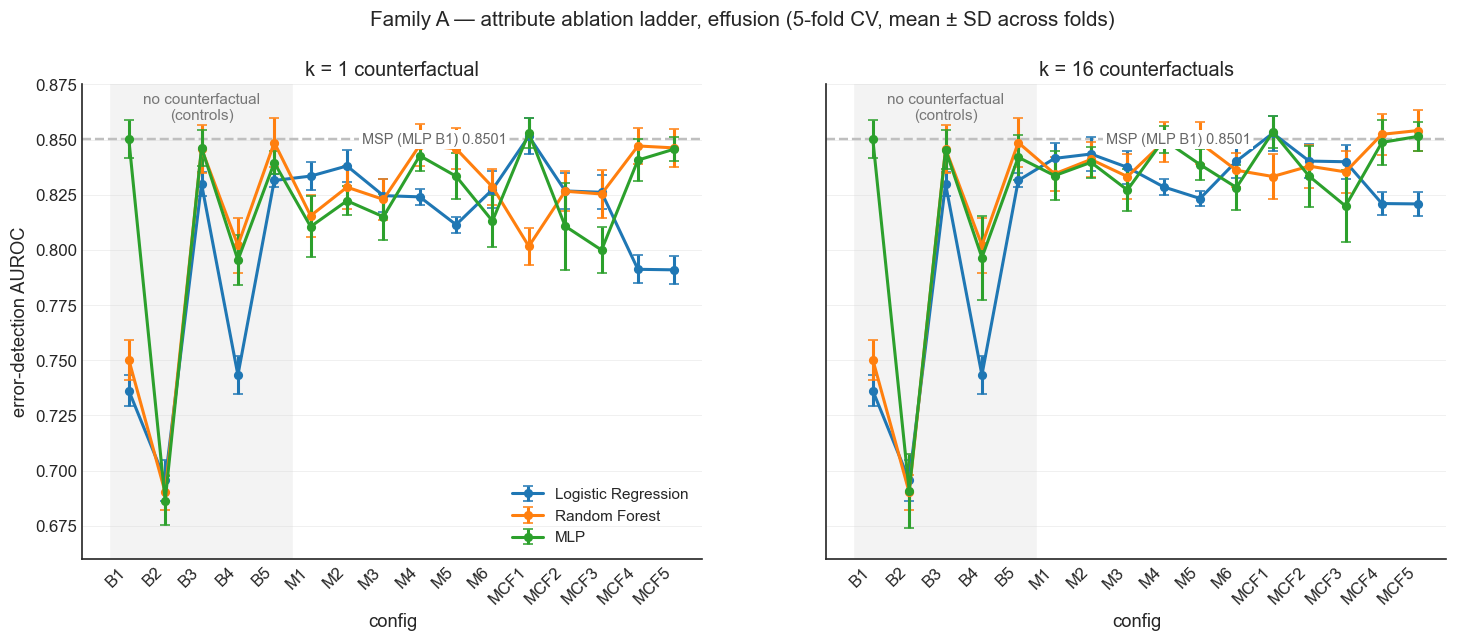

In [ ]:
# ── Fig 4a — the ablation ladder ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), sharey=True)
x = np.arange(len(CONFIG_ORDER))

for ax, k in zip(axes, (1, 16)):
    auc_t, std_t = attrA[k]['auc'], attrA[k]['std']
    ax.axvspan(-0.5, 4.5, color='#F3F3F3', zorder=0)
    ax.text(2.0, 0.8715, 'no counterfactual\n(controls)', ha='center', va='top',
            fontsize=10, color='#777777')

    for m in MODELS:
        ax.errorbar(x, auc_t[m].values, yerr=std_t[m].values, marker='o', ms=5,
                    capsize=3, lw=2.0, label=MODEL_NAMES[m])

    ax.axhline(B1_BEST, color=PLOT_COLORS['B1'], ls=PLOT_LS['B1'], lw=1.6, zorder=1)
    ax.text(6.4, B1_BEST, f'MSP ({B1_BEST_MODEL} B1) {B1_BEST:.4f}',
            ha='left', va='center', fontsize=9.5, color='#666666',
            bbox=dict(fc='white', ec='none', pad=1.5))
    ax.set(xticks=x, title=f'k = {k} counterfactual{"s" if k > 1 else ""}',
           xlabel='config', ylim=(0.66, 0.875))
    ax.set_xticklabels(CONFIG_ORDER, rotation=45, ha='right')
    ax.grid(axis='y', alpha=0.3)

axes[0].set_ylabel('error-detection AUROC')
axes[0].legend(frameon=False, loc='lower right')
fig.suptitle(f'Family A — attribute ablation ladder, {DISEASE} '
             f'(5-fold CV, mean ± SD across folds)', y=1.0, fontsize=13.5)
fig.savefig(f'{OUT}/story_famA_ladder_{DISEASE}.png')
plt.show()

In [ ]:
# ── Table 4a — the same numbers, with the delta that matters ──────────────────
tbl = attrA[1]['auc'].round(4).copy()
tbl.columns = [f'{c} (k=1)' for c in tbl.columns]
tbl16 = attrA[16]['auc'].round(4)
tbl16.columns = [f'{c} (k=16)' for c in tbl16.columns]
tbl = tbl.join(tbl16)
tbl.insert(0, 'features', [CONFIG_DESC[c] for c in tbl.index])
tbl['best any'] = attrA[1]['auc'].join(attrA[16]['auc'], lsuffix='1',
                                       rsuffix='16').max(axis=1).round(4)
tbl['vs MSP'] = (tbl['best any'] - B1_BEST).round(4)
tbl['CF-free?'] = ['control' if c in NO_CF_CONFIGS else '' for c in tbl.index]
tbl

,features,LR (k=1),MLP (k=1),RF (k=1),LR (k=16),MLP (k=16),RF (k=16),best any,vs MSP,CF-free?
config,,,,,,,,,,
B1,prob,0.7362,0.8501,0.7502,0.7362,0.8501,0.7502,0.8501,0.0000,control
B2,attr,0.6956,0.6864,0.6901,0.6956,0.6908,0.6901,0.6956,-0.1545,control
B3,emb,0.8299,0.8464,0.8458,0.8299,0.8455,0.8458,0.8464,-0.0037,control
B4,prob + attr,0.7433,0.7954,0.8021,0.7433,0.7965,0.8021,0.8021,-0.0480,control
B5,prob + emb,0.8315,0.8395,0.8487,0.8315,0.8420,0.8487,0.8487,-0.0014,control
M1,delta,0.8335,0.8106,0.8155,0.8415,0.8337,0.8345,0.8415,-0.0086,
M2,prob + delta,0.8381,0.8223,0.8284,0.8435,0.8397,0.8410,0.8435,-0.0066,
M3,prob + delta + attr,0.8246,0.8150,0.8229,0.8374,0.8271,0.8332,0.8374,-0.0127,
M4,prob + delta + emb,0.8240,0.8427,0.8475,0.8285,0.8500,0.8489,0.8500,-0.0001,


**Reading the ladder.**

1. **Δ-attributes alone (`M1`) do not carry the signal.** `M1` is far below `B1`; the
   ladder only becomes competitive once `prob` is in the design matrix. Whatever the
   Δ-vector contributes, it is not a standalone correctness score.
2. **`B5` — prob + embedding, *no counterfactual* — is already at the top of the range.**
   This is the comparator that the superseded run was missing, and it reframes the result:
   most of what `M4`/`M5`/`MCF4`/`MCF5` achieve is available without generating a
   counterfactual at all.
3. **The counterfactual-attributable gain is small.** The best CF-bearing config exceeds
   the best MSP fit by ~0.003–0.004 AUROC. §4.3 tests whether that survives DeLong.
4. **k = 16 buys very little over k = 1.** Averaging 16 counterfactual expansions moves
   the best config by a few thousandths — consistent with retrieval measuring a
   boundary distance that one neighbour already estimates.

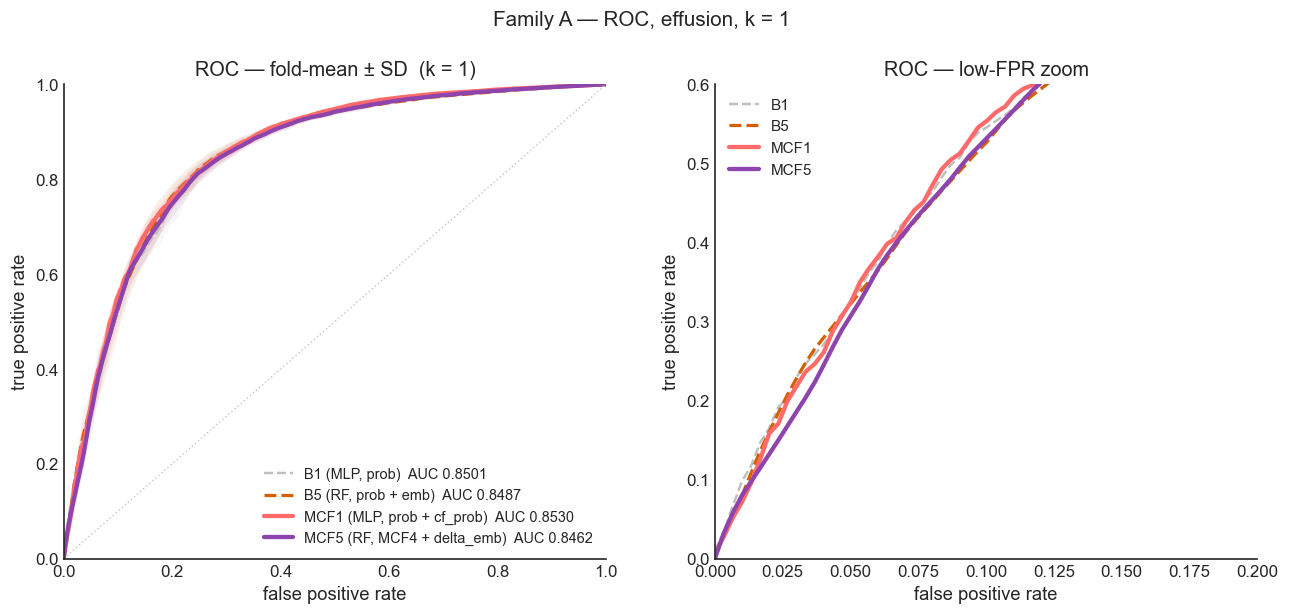

In [ ]:
# ── Fig 4b — ROC curves, best model per selected config ───────────────────────
# Four representative configs: the MSP baseline, the strongest CF-free control, the
# cheapest CF config, and the richest one.
SHOW = ['B1', 'B5', 'MCF1', 'MCF5']
K_ROC = 1

best_model = {c: attrA[K_ROC]['auc'].loc[c].idxmax() for c in SHOW}
det = attrA[K_ROC]['detailed']

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for c in SHOW:
    m = best_model[c]
    s = summarise(det[m][c])
    axes[0].plot(s['fpr'], s['tpr'], color=PLOT_COLORS[c], ls=PLOT_LS[c],
                 lw=PLOT_LW[c] + 0.6,
                 label=f'{c} ({m}, {CONFIG_DESC[c]})  AUC {s["auc"]:.4f}')
    axes[0].fill_between(s['fpr'], s['tpr'] - s['std'], s['tpr'] + s['std'],
                         color=PLOT_COLORS[c], alpha=0.10, lw=0)

axes[0].plot([0, 1], [0, 1], color='#CCCCCC', lw=1, ls=':')
axes[0].set(xlabel='false positive rate', ylabel='true positive rate',
            title=f'ROC — fold-mean ± SD  (k = {K_ROC})', xlim=(0, 1), ylim=(0, 1))
axes[0].legend(frameon=False, loc='lower right', fontsize=9.5)

# Zoom on the low-FPR corner: the operating region a radiology workflow would actually use.
for c in SHOW:
    s = summarise(det[best_model[c]][c])
    axes[1].plot(s['fpr'], s['tpr'], color=PLOT_COLORS[c], ls=PLOT_LS[c],
                 lw=PLOT_LW[c] + 0.6, label=c)
axes[1].set(xlim=(0, 0.2), ylim=(0, 0.6), xlabel='false positive rate',
            ylabel='true positive rate', title='ROC — low-FPR zoom')
axes[1].legend(frameon=False, loc='upper left')

fig.suptitle(f'Family A — ROC, {DISEASE}, k = {K_ROC}', y=1.0, fontsize=13.5)
fig.savefig(f'{OUT}/story_famA_roc_{DISEASE}.png')
plt.show()

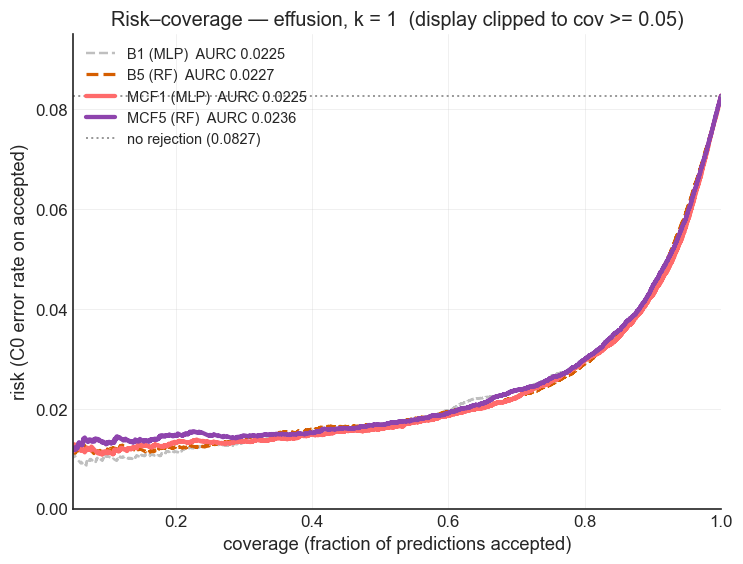

,config,model,features,AURC,risk @ 80% cov,risk @ 50% cov,AURC vs B1
0,B1,MLP,prob,0.0225,0.0294,0.0159,0.0000
1,B5,RF,prob + emb,0.0227,0.0290,0.0167,0.0002
2,MCF1,MLP,prob + cf_prob,0.0225,0.0297,0.0160,0.0000
3,MCF5,RF,MCF4 + delta_emb,0.0236,0.0299,0.0168,0.0011


In [ ]:
# ── Fig 4c — risk-coverage and AURC ───────────────────────────────────────────
# The proposal's second headline metric. Risk = C0 error rate among ACCEPTED predictions
# after C2 rejects the lowest-scoring tail. Lower curve = better; AURC integrates it.
fig, ax = plt.subplots(figsize=(7.6, 5.6))
aurc_rows = []

for c in SHOW:
    m = best_model[c]
    y, p = pooled_oof(det[m][c])
    cov, risk, aurc = risk_coverage(p, y)
    ax.plot(cov, risk, color=PLOT_COLORS[c], ls=PLOT_LS[c], lw=PLOT_LW[c] + 0.6,
            label=f'{c} ({m})  AURC {aurc:.4f}')
    aurc_rows.append({'config': c, 'model': m, 'features': CONFIG_DESC[c],
                      'AURC': round(aurc, 4),
                      'risk @ 80% cov': round(float(risk[int(0.8 * len(risk)) - 1]), 4),
                      'risk @ 50% cov': round(float(risk[int(0.5 * len(risk)) - 1]), 4)})

_base_risk = 1 - c2['correct'].mean()
ax.axhline(_base_risk, color='#999999', ls=':', lw=1.3,
           label=f'no rejection ({_base_risk:.4f})')
# AURC is integrated over the FULL curve, but the display is clipped to coverage >= 0.05:
# below that the accepted set is a few hundred images and the error rate is pure noise,
# which otherwise compresses every curve into a flat line.
ax.set(xlabel='coverage (fraction of predictions accepted)',
       ylabel='risk (C0 error rate on accepted)',
       xlim=(0.05, 1.0), ylim=(0, 0.095),
       title=f'Risk–coverage — {DISEASE}, k = {K_ROC}  (display clipped to cov >= 0.05)')
ax.legend(frameon=False, loc='upper left', fontsize=9.5)
ax.grid(alpha=0.3)
fig.savefig(f'{OUT}/story_famA_riskcoverage_{DISEASE}.png')
plt.show()

aurc_df = pd.DataFrame(aurc_rows)
aurc_df['AURC vs B1'] = (aurc_df['AURC'] - aurc_df.loc[aurc_df.config == 'B1',
                                                       'AURC'].iloc[0]).round(4)
aurc_df

### §4.3 — Is the win over MSP real?

Five fold-level AUCs give a paired test 4 degrees of freedom and almost no power at
effect sizes of ~0.004. Instead each config's five held-out folds are concatenated into
one out-of-fold score vector (one prediction per image, n ≈ 45k) and compared against the
MSP baseline with **DeLong's test for two correlated AUCs**.

In [ ]:
# ── Table 4d — DeLong, every config vs the MSP baseline ───────────────────────
y_ref, p_ref = pooled_oof(det[B1_BEST_MODEL]['B1'])

rows = []
for c in CONFIG_ORDER:
    for m in MODELS:
        y_c, p_c = pooled_oof(det[m][c])
        # Same folds, same order -> the label vectors must be identical elementwise.
        assert np.array_equal(y_c, y_ref), f'{m}/{c}: OOF labels misaligned'
        a_c, a_b, pv = delong_test(y_ref, p_c, p_ref)
        rows.append({'config': c, 'model': m, 'features': CONFIG_DESC[c],
                     'CF-free': c in NO_CF_CONFIGS,
                     'AUROC (pooled OOF)': round(a_c, 4),
                     'delta vs MSP': round(a_c - a_b, 4),
                     'p (DeLong)': pv})

delong_df = pd.DataFrame(rows)
delong_df['significant'] = np.where(
    delong_df['p (DeLong)'] < 0.05,
    np.where(delong_df['delta vs MSP'] > 0, 'better', 'worse'), '—')
delong_df['p (DeLong)'] = delong_df['p (DeLong)'].map(
    lambda v: '<1e-4' if v < 1e-4 else f'{v:.4f}')

print(f'reference: {B1_BEST_MODEL} B1 (MSP), pooled OOF AUROC = '
      f'{roc_auc_score(y_ref, p_ref):.4f}, n = {len(y_ref):,}\n')
delong_df.sort_values('AUROC (pooled OOF)', ascending=False).head(20).reset_index(drop=True)

reference: MLP B1 (MSP), pooled OOF AUROC = 0.8494, n = 45,155



,config,model,features,CF-free,AUROC (pooled OOF),delta vs MSP,p (DeLong),significant
0,MCF1,MLP,prob + cf_prob,False,0.8523,0.0029,0.0009,better
1,MCF1,LR,prob + cf_prob,False,0.8513,0.0019,0.0165,better
2,B1,MLP,prob,True,0.8494,0.0000,1.0000,—
3,B5,RF,prob + emb,True,0.8484,-0.0011,0.5447,—
4,M4,RF,prob + delta + emb,False,0.8472,-0.0023,0.1888,—
5,MCF4,RF,MCF3 + emb + cf_emb,False,0.8469,-0.0026,0.1547,—
6,MCF5,RF,MCF4 + delta_emb,False,0.8461,-0.0034,0.0692,—
7,M5,RF,prob + delta + attr + emb,False,0.8457,-0.0038,0.0395,worse
8,B3,RF,emb,True,0.8455,-0.0040,0.0268,worse
9,B3,MLP,emb,True,0.8451,-0.0044,0.0200,worse


In [ ]:
# ── The headline sentence, computed ───────────────────────────────────────────
cf_only  = delong_df[~delong_df['CF-free']]
ctrl_only = delong_df[delong_df['CF-free'] & (delong_df.config != 'B1')]

best_cf   = cf_only.loc[cf_only['AUROC (pooled OOF)'].idxmax()]
best_ctrl = ctrl_only.loc[ctrl_only['AUROC (pooled OOF)'].idxmax()]

print('Family A, effusion, k = 1, pooled out-of-fold\n' + '=' * 62)
print(f'  MSP baseline (B1)            : {roc_auc_score(y_ref, p_ref):.4f}')
print(f'  best CF-FREE control         : {best_ctrl.model} {best_ctrl.config}  '
      f'{best_ctrl["AUROC (pooled OOF)"]:.4f}   '
      f'({best_ctrl["delta vs MSP"]:+.4f}, p {best_ctrl["p (DeLong)"]})')
print(f'  best COUNTERFACTUAL config   : {best_cf.model} {best_cf.config}  '
      f'{best_cf["AUROC (pooled OOF)"]:.4f}   '
      f'({best_cf["delta vs MSP"]:+.4f}, p {best_cf["p (DeLong)"]})')
print(f'\n  counterfactual gain OVER the best CF-free control: '
      f'{best_cf["AUROC (pooled OOF)"] - best_ctrl["AUROC (pooled OOF)"]:+.4f}')
print('\nThat last number -- not the gain over B1 -- is what is attributable to the')
print('counterfactual, because B3/B5 already contain the embedding.')

Family A, effusion, k = 1, pooled out-of-fold
  MSP baseline (B1)            : 0.8494
  best CF-FREE control         : RF B5  0.8484   (-0.0011, p 0.5447)
  best COUNTERFACTUAL config   : MLP MCF1  0.8523   (+0.0029, p 0.0009)

  counterfactual gain OVER the best CF-free control: +0.0039

That last number -- not the gain over B1 -- is what is attributable to the
counterfactual, because B3/B5 already contain the embedding.


### §4.4 — Does the signal survive clean labels? The official CheXpert test set

Everything above is measured on C0's held-out half of `train.csv`, whose labels come from
the CheXpert **NLP labeller**. §7 names label noise as a limit on the evaluation, so this
section runs the same Family-A ladder against the one CheXpert split that does not have it:
`valid.csv` — 234 images from 200 patients, of which **202 are frontal**, labelled by
**three board-certified radiologists**.

**This is a genuine external test, not a re-slice.** C0 has never seen these patients
(`c0_custom_split.py` splits `train.csv` 50/50 at patient level; valid patients are numbered
64541+), and no C2 model has either. The run trains one model per (model, config) on the
**full 45,155-row cohort** and scores the 202 test rows once. Counterfactuals are retrieved
from the training cohort, exactly as in cross-validation.

Three things make this test harder than a re-slice, and they are the point:

1. **The C2 target changes meaning.** C2 is trained to predict correctness against a noisy
   proxy label and tested against correctness under expert labels.
2. **The prior shifts hard.** The training cohort is 76.5% effusion-positive; the test set is
   31.7%. C0's fixed operating point does not move with it.
3. **The input distribution shifts** for every attribute and embedding feature.

`code/c0/c0_predict_chexpert_test.py` → `code/c1/c1_match_chexpert_test.py` →
`code/c2/c2_external_test_cf_ensemble.py`, the last of which *imports* its retrieval,
feature blocks and config definitions from `c2_cv_pipeline_cf_ensemble.py` so a difference
here cannot be an artefact of redefined features.

In [ ]:
# ── Register the external run alongside the CV runs ───────────────────────────
from sklearn.metrics import roc_curve   # cell 2 imports only roc_auc_score

# Same five-segment path grammar as the CV tree, under an external_test/ root so it
# can never land on top of a cross-validation result.
EXT_RUN = (f'{RESULTS}/C2_custom_corrected/{DISEASE}/external_test/chexpert_test/'
           'cf_16/distance_l1/strategy_correct_cf/TEST_entropy_added(M-only)')
RUNS['attrA_ext'] = EXT_RUN
SOURCES['c0_ext']     = f'{RESULTS}/C0_custom/{DISEASE}/chexperttest_c0_{DISEASE}.csv'
SOURCES['c2_ext']     = f'{RESULTS}/C2_custom/{DISEASE}/c2_data_chexpert_test.csv'
SOURCES['chex_valid'] = f'{DATA}/CheXpert-v1.0-small/valid.csv'

_ext_missing = [k for k in ('attrA_ext',) if not os.path.exists(RUNS[k])] + \
               [k for k in ('c0_ext', 'c2_ext', 'chex_valid') if not os.path.exists(SOURCES[k])]
assert not _ext_missing, (
    f'External-test artefacts missing: {_ext_missing}. Produce them with\n'
    f'  bsub < $BASE/jobs/external_test/run_c0_chexpert_test.sh\n'
    f'  python $BASE/code/c1/c1_match_chexpert_test.py --disease {DISEASE}\n'
    f'  bsub < $BASE/jobs/external_test/run_c2_external_test.sh')

with open(os.path.join(EXT_RUN, 'run_config.json')) as fh:
    EXT_CFG = json.load(fh)

ext_sum = load_summary('attrA_ext')
ext_det = load_detailed('attrA_ext')

# The k=16 ensemble is the headline; rank 0 of the SAME run is the k=1 result, so both
# arrive from one job (single_cf_auc). No separate k=1 run exists or is needed.
print(f"external test : {EXT_CFG['n_test']} rows, "
      f"{EXT_CFG['n_test_errors']} of them C0 errors")
print(f"trained on    : {EXT_CFG['n_train']:,} rows  ({os.path.basename(EXT_CFG['train_csv'])})")
print(f"k             : {EXT_CFG['cf_count']}  (rank 0 = the k=1 result)")
print(f"bootstrap     : {EXT_CFG['n_bootstrap']} patient-level resamples per config")
print(f"\n{len(ext_sum)} rows: {sorted(ext_sum['model'].unique())} x {len(CONFIG_ORDER)} configs "
      f"+ the training-free MSP baseline")
ext_sum.head(3)

#### C0 under prior shift — read this before the ladder

The single most consequential number in this section is not a C2 AUROC. It is that C0's
**accuracy falls from 91.7% to 77.2%** while its **AUC only falls from 0.954 to 0.905**.

Ranking ability largely survives; the *operating point* does not. The threshold was tuned on
a 76.5%-positive cohort and is being applied to a 31.7%-positive one, so C0 over-calls
effusion: **37 of its 46 errors are false positives**.

That is not purely a calibration artefact — a Youden-optimal threshold fitted *on the test set
itself* (which would be cheating, shown only as a floor) still leaves 38 errors. But it does
mean the external error set is a different *kind* of error set from the one C2 was trained on,
which is the sharpest available test of whether the counterfactual signal is general.

The upside is statistical: **46 errors out of 202** is a far healthier minority class than the
~17 a 91.7%-accurate classifier would have produced, so the bootstrap intervals below are
narrower than they might have been.

In [ ]:
# ── C0: noisy holdout vs expert-labelled test set ─────────────────────────────
# The operating threshold is recovered from c2_data.csv's margin column rather than read
# from threshold.txt. threshold.txt holds the rounded 0.5634; the value actually used to
# label `correct` throughout this project is 0.562932252884 (margin = |prob - t| for every
# row, so t is exactly recoverable). The difference flips 5 of 45,155 training rows -- an
# irrelevant amount, but there is no reason for the external test to sit at a different
# operating point than the data C2 trained on.
_m = pd.read_csv(SOURCES['c2_data'], usecols=['prob', 'pred', 'margin'], nrows=20000)
_t = np.where(_m['pred'] == 0, _m['prob'] + _m['margin'], _m['prob'] - _m['margin'])
assert np.ptp(_t) < 1e-9, 'margin column is not consistent with a single threshold'
C0_THRESH_EXACT = float(np.median(_t))
print(f'operating threshold : {C0_THRESH_EXACT:.12f}  (recovered; threshold.txt says {C0_THRESH})\n')

c2_tr = c2                      # the C2 cohort, already loaded in §1
c0_ex = pd.read_csv(SOURCES['c0_ext'], usecols=['path', 'prob', 'true'])


def _c0_row(name, prob, true, t):
    pred = (prob > t).astype(int)
    corr = (pred == true).astype(int)
    return {'cohort': name, 'n': len(prob), 'prevalence': true.mean(),
            'mean prob': prob.mean(), 'AUC': roc_auc_score(true, prob),
            'accuracy': corr.mean(), 'errors': int((corr == 0).sum()),
            'FP': int(((pred == 1) & (true == 0)).sum()),
            'FN': int(((pred == 0) & (true == 1)).sum())}


shift = pd.DataFrame([
    _c0_row('C0 held-out (NLP labels)', c2_tr['prob'].values, c2_tr['true'].values, C0_THRESH_EXACT),
    _c0_row('CheXpert test (expert)',   c0_ex['prob'].values, c0_ex['true'].values, C0_THRESH_EXACT),
])
print(shift.to_string(index=False, float_format=lambda v: f'{v:.4f}'))

# How much of the external error set is the operating point, and how much is C0?
_fpr, _tpr, _thr = roc_curve(c0_ex['true'], c0_ex['prob'])
_youden = float(_thr[np.argmax(_tpr - _fpr)])
sens = pd.DataFrame([
    _c0_row(f'transferred  t={C0_THRESH_EXACT:.4f}', c0_ex['prob'].values, c0_ex['true'].values, C0_THRESH_EXACT),
    _c0_row('fixed        t=0.5000',                 c0_ex['prob'].values, c0_ex['true'].values, 0.5),
    _c0_row(f'Youden-on-test t={_youden:.4f} (leaky floor)', c0_ex['prob'].values, c0_ex['true'].values, _youden),
])
print('\nOperating-point sensitivity on the 202-image test set:')
print(sens[['cohort', 'accuracy', 'errors', 'FP', 'FN']].to_string(index=False,
      float_format=lambda v: f'{v:.4f}'))
print('\n-> even a threshold fitted ON the test set leaves 38 errors, so the external error')
print('   set is not merely a miscalibration artefact.')

In [ ]:
# ── Fig 4e — the ladder, cross-validated vs external ──────────────────────────
cv16 = attrA[16]['auc']                       # configs x models, mean fold AUC
ext_msp = float(ext_sum.loc[ext_sum['config'] == 'MSP', 'auc'].iloc[0])

fig, axes = plt.subplots(1, 3, figsize=(19, 5.4), sharey=True)
x = np.arange(len(CONFIG_ORDER))

for ax, m in zip(axes, MODELS):
    e = ext_sum[ext_sum['model'] == m].set_index('config').reindex(CONFIG_ORDER)

    ax.axvspan(-0.5, 4.5, color='#F3F3F3', zorder=0)

    # External: point estimate with the patient-level bootstrap interval.
    ax.errorbar(x, e['auc'].values,
                yerr=np.vstack([e['auc'].values - e['auc_lo'].values,
                                e['auc_hi'].values - e['auc'].values]),
                marker='o', ms=5.5, capsize=3, lw=2.2, color='#0072B2',
                label='external test (n=202, 95% CI)', zorder=4)

    # Cross-validated reference, same k.
    ax.plot(x, cv16[m].reindex(CONFIG_ORDER).values, marker='s', ms=4.5, lw=1.8,
            ls='-', color='#009E73', alpha=0.85, label='5-fold CV (n=45,155)', zorder=3)

    # B1 = the confidence-only control, as a thin reference line (house rule).
    _b1 = float(e.loc['B1', 'auc'])
    ax.axhline(_b1, color=PLOT_COLORS['B1'], ls=PLOT_LS['B1'], lw=PLOT_LW['B1'], zorder=1)
    # MSP, training-free: the only baseline on this set that cannot be blamed on sample size.
    ax.axhline(ext_msp, color='#CC0000', ls=':', lw=1.6, zorder=2)

    ax.set(xticks=x, title=MODEL_NAMES[m], xlabel='config')
    ax.set_xticklabels(CONFIG_ORDER, rotation=45, ha='right')
    ax.grid(axis='y', alpha=0.3)

axes[0].text(2.0, 0.985, 'no counterfactual\n(controls)', ha='center', va='top',
             fontsize=9.5, color='#777777', transform=axes[0].get_xaxis_transform())
axes[0].set_ylabel('error-detection AUROC')
_h, _l = axes[0].get_legend_handles_labels()
_h += [Line2D([], [], color=PLOT_COLORS['B1'], ls=PLOT_LS['B1'], lw=PLOT_LW['B1']),
       Line2D([], [], color='#CC0000', ls=':', lw=1.6)]
_l += ['B1 (prob only), external', f'MSP training-free ({ext_msp:.3f})']
axes[0].legend(_h, _l, frameon=False, loc='lower right', fontsize=9)
fig.suptitle(f'Fig 4e — Family A on the expert-labelled CheXpert test set, {DISEASE} '
             f'(k=16; {EXT_CFG["n_test_errors"]} errors in {EXT_CFG["n_test"]} images)',
             y=1.0, fontsize=13.5)
fig.savefig(f'{OUT}/story_famA_external_{DISEASE}.png')
plt.show()

In [ ]:
# ── Does the ladder keep its SHAPE? ───────────────────────────────────────────
# With 46 errors the external point estimates are individually noisy, so the question that
# CAN be answered is whether the ordering of the configs transfers. Spearman rho over the
# 16 configs, per model, plus the pooled scatter.
rows, pooled_cv, pooled_ext, pooled_lab = [], [], [], []
for m in MODELS:
    e = ext_sum[ext_sum['model'] == m].set_index('config').reindex(CONFIG_ORDER)
    c = cv16[m].reindex(CONFIG_ORDER)
    rho, p = stats.spearmanr(c.values, e['auc'].values)
    rows.append({'model': m, 'spearman rho': rho, 'p': p,
                 'mean CV AUC': c.mean(), 'mean external AUC': e['auc'].mean(),
                 'mean shift': e['auc'].mean() - c.mean(),
                 'median CI width': e['ci_width'].median()})
    pooled_cv += list(c.values); pooled_ext += list(e['auc'].values)
    pooled_lab += [(m, cfg) for cfg in CONFIG_ORDER]

rank_tbl = pd.DataFrame(rows)
print('Config ordering, cross-validated vs external:')
print(rank_tbl.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
_rho, _p = stats.spearmanr(pooled_cv, pooled_ext)
print(f'\npooled over all {len(pooled_cv)} (model, config) pairs: rho = {_rho:.3f}, p = {_p:.2g}')

fig, ax = plt.subplots(figsize=(6.4, 6.0))
for m, mk in zip(MODELS, ('o', 's', '^')):
    sel = [i for i, (mm, _) in enumerate(pooled_lab) if mm == m]
    ax.scatter([pooled_cv[i] for i in sel], [pooled_ext[i] for i in sel],
               marker=mk, s=46, alpha=0.85, label=MODEL_NAMES[m])
lims = [min(pooled_cv + pooled_ext) - 0.02, max(pooled_cv + pooled_ext) + 0.02]
ax.plot(lims, lims, ls='--', lw=1.2, color='#BFBFBF', zorder=0)
ax.axhline(ext_msp, color='#CC0000', ls=':', lw=1.4, zorder=0)
ax.text(lims[0] + 0.005, ext_msp + 0.004, 'MSP (external, training-free)',
        fontsize=9, color='#CC0000')
ax.set(xlim=lims, ylim=lims, xlabel='AUROC — 5-fold CV (n=45,155)',
       ylabel='AUROC — external test (n=202)',
       title=f'Every (model, config) pair\npooled Spearman rho = {_rho:.3f}')
ax.legend(frameon=False, loc='lower right')
ax.grid(alpha=0.3)
fig.savefig(f'{OUT}/story_famA_external_scatter_{DISEASE}.png')
plt.show()

In [ ]:
# ── Table 4e — every config against the training-free MSP baseline ────────────
# DeLong on the SAME 202 samples. The comparator is MSP rather than a fitted B1, because
# on a 202-row test set a training-free score is the one reference that cannot be
# confounded by how much data the fitted models saw.
msp_scores = np.asarray(ext_det['NONE']['MSP'][0]['y_prob'], float)
y_ext      = np.asarray(ext_det['NONE']['MSP'][0]['y_true'], int)

rows = []
for m in MODELS:
    for cfg in CONFIG_ORDER:
        f = ext_det[m][cfg][0]
        s = np.asarray(f['y_prob'], float)
        assert np.array_equal(np.asarray(f['y_true'], int), y_ext), 'sample order differs'
        a_cfg, a_msp, p = delong_test(y_ext, s, msp_scores)
        rows.append({'model': m, 'config': cfg, 'features': CONFIG_DESC[cfg],
                     'AUROC': a_cfg, 'CI low': f['auc_lo'], 'CI high': f['auc_hi'],
                     'k=1 (rank 0)': f['member_aucs'][0],
                     'vs MSP': a_cfg - a_msp, 'DeLong p': p, 'AURC': f['aurc']})

ext_tbl = pd.DataFrame(rows)
print(f'MSP (training-free, |prob - t|) = {a_msp:.4f}   '
      f'[{ext_det["NONE"]["MSP"][0]["auc_lo"]:.4f}, {ext_det["NONE"]["MSP"][0]["auc_hi"]:.4f}]\n')
print('Top 12 by external AUROC:')
print(ext_tbl.sort_values('AUROC', ascending=False).head(12)
      .to_string(index=False, float_format=lambda v: f'{v:.4f}'))

_sig = ext_tbl[ext_tbl['DeLong p'] < 0.05]
print(f'\n{len(_sig)} of {len(ext_tbl)} (model, config) pairs differ from MSP at p < 0.05'
      f' on these {len(y_ext)} samples.')
if len(_sig):
    print(_sig[['model', 'config', 'AUROC', 'vs MSP', 'DeLong p']]
          .sort_values('vs MSP', ascending=False)
          .to_string(index=False, float_format=lambda v: f'{v:.4f}'))

In [ ]:
# ── Fig 4f — risk-coverage on the expert-labelled set ─────────────────────────
# The deployment view: at each coverage, what fraction of ACCEPTED predictions is wrong.
# Base risk here is 46/202 = 22.8%, far above the 8.3% of the noisy holdout, so the curves
# have room to separate.
best = (ext_tbl.sort_values('AUROC', ascending=False)
        .drop_duplicates('config').head(4)[['model', 'config']].values.tolist())

fig, ax = plt.subplots(figsize=(7.4, 5.6))
cov, risk, aurc = risk_coverage(msp_scores, y_ext)
ax.plot(cov, risk, color='#CC0000', ls=':', lw=2.0,
        label=f'MSP training-free (AURC {aurc:.4f})')

for m, cfg in best:
    s = np.asarray(ext_det[m][cfg][0]['y_prob'], float)
    cov, risk, aurc = risk_coverage(s, y_ext)
    ax.plot(cov, risk, color=PLOT_COLORS.get(cfg, '#333333'),
            ls=PLOT_LS.get(cfg, '-'), lw=PLOT_LW.get(cfg, 2.0),
            label=f'{m} {cfg} — {CONFIG_DESC[cfg]} (AURC {aurc:.4f})')

_base = 1 - y_ext.mean()
ax.axhline(_base, color='#999999', ls='--', lw=1.1)
ax.text(0.02, _base + 0.006, f'no rejection: {_base:.1%} error rate', fontsize=9, color='#666666')
ax.set(xlabel='coverage', ylabel='risk (error rate among accepted)',
       title=f'Fig 4f — risk–coverage, expert-labelled CheXpert test set '
             f'({EXT_CFG["n_test_errors"]}/{EXT_CFG["n_test"]} errors)')
ax.legend(frameon=False, fontsize=9, loc='upper left')
ax.grid(alpha=0.3)
fig.savefig(f'{OUT}/story_famA_external_rc_{DISEASE}.png')
plt.show()

In [ ]:
# ── The §4.4 sentence, computed ───────────────────────────────────────────────
_best = ext_tbl.sort_values('AUROC', ascending=False).iloc[0]
_b1   = ext_tbl[(ext_tbl.config == 'B1')].sort_values('AUROC', ascending=False).iloc[0]
_cf   = ext_tbl[~ext_tbl.config.isin(NO_CF_CONFIGS)].sort_values('AUROC', ascending=False).iloc[0]
_ctrl = ext_tbl[ext_tbl.config.isin(NO_CF_CONFIGS)].sort_values('AUROC', ascending=False).iloc[0]

print(f'''
On the {EXT_CFG['n_test']} expert-labelled CheXpert test images ({EXT_CFG['n_test_errors']} C0 errors):

  training-free MSP            {a_msp:.4f}
  best CF-free control         {_ctrl['model']:>3} {_ctrl['config']:<5} {_ctrl['AUROC']:.4f}  [{_ctrl['CI low']:.4f}, {_ctrl['CI high']:.4f}]
  best counterfactual config   {_cf['model']:>3} {_cf['config']:<5} {_cf['AUROC']:.4f}  [{_cf['CI low']:.4f}, {_cf['CI high']:.4f}]
  best overall                 {_best['model']:>3} {_best['config']:<5} {_best['AUROC']:.4f}  (DeLong vs MSP p = {_best['DeLong p']:.3f})

  best CF config minus best CF-free control : {_cf['AUROC'] - _ctrl['AUROC']:+.4f}
  pooled config-ordering agreement with CV  : Spearman rho = {_rho:.3f} (p = {_p:.2g})

  Median 95% CI width across configs: {ext_sum['ci_width'].median():.4f}
  -> a gap must exceed roughly {ext_sum['ci_width'].median()/2:.2f} AUROC to be resolvable here.
''')

#### What §4.4 establishes, and what it cannot

**Can conclude.** The ladder was trained on NLP-labelled data and evaluated against
radiologist labels, on patients no part of the pipeline has seen, under a prevalence shift
from 76.5% to 31.7% positive. Whatever ordering survives that is not an artefact of the
label noise §7 flags, and is not an artefact of the cross-validation split.

**Cannot conclude.** With 46 errors, the median 95% CI on a single AUROC is printed above and
is wide. This set cannot adjudicate the 0.01–0.02 differences that separate the top configs
in §4.2 — it was never going to. Read the *ranking* and the *sign* of each gap; treat any
individual point estimate as a coarse check.

**The comparator is MSP, not a fitted B1.** On 202 rows every fitted model, baselines
included, is exposed to the same train/test shift, so a fitted baseline is not a clean
reference. `|prob − t|` is computed directly from C0's output and is the plain softmax
baseline that [Bernhardt 2022] and [Bungert 2023] report no learned rejector beating; it is
the honest thing to beat here.

**Not covered.** Families B and C have no external run. The Grad-CAMs for these 202 images
were written by the same job (`gradcam/chexpert_test/`) and `test_predictions.csv` carries the
`cf_paths` pairing, so Family B is one CNN inference away; Family C is not, because the
diffusion grid is its own 5,431-image cohort. Pneumothorax cannot be run this way at all —
the official test set holds only 7 positives.

---
## §5 — Family B: image-based C2

> *Assumption:* the signal is inherently **spatial**, and is partly destroyed when the
> change is projected onto a scalar Δ-attribute vector.

A DenseNet121 consumes the query, its counterfactual, and the C0 Grad-CAM saliency of
each, through separate encoders fused at the classifier head
(`code/CNN_baselines/c2_cnn_all.py`). The intended ablation walks up the input channels:
`xi` → `xi + saliency` → `dual` (query + CF) → `dual + saliency` →
`dual + saliency + scalars`.

### ⚠ This family is currently one data point

The patient-leak fix on 2026-07-16 invalidated the entire CNN sweep. Exactly **one**
post-fix CNN run exists per disease — `late / dual_sal_scalars / cf_16`, the top rung of
the ladder. Every other rung, every early-fusion variant, and every k ∈ {1, 3, 5} run now
lives under `results/archive_preleak_2026-07-16/` and is patient-leaky.

Per the plan, no pre-fix numbers are plotted here. What is missing is enumerated in §7
(gap table rows 4–5). The consequence for the thesis is that **the channel ablation
promised in Aim 2 for the image family has no valid data yet** — the single surviving
point cannot separate the contribution of saliency from that of the counterfactual.

In [ ]:
# ── The one valid CNN run, against the Family-A reference ─────────────────────
cnn_sum = pd.read_csv(os.path.join(RUNS['cnnB_k16'], 'cv_summary.csv'))
with open(os.path.join(RUNS['cnnB_k16'], 'cv_detailed.json')) as fh:
    cnn_det = json.load(fh)           # list of 5 fold dicts

cnn_auc  = float(cnn_sum['auc'].mean())
cnn_std  = float(cnn_sum['auc'].std())
cnn_summ = summarise(cnn_det)

famA_k16 = attrA[16]['auc']
famA_best_cfg = famA_k16.max(axis=1).idxmax()
famA_best_mod = famA_k16.loc[famA_best_cfg].idxmax()
famA_best_auc = float(famA_k16.loc[famA_best_cfg].max())

cmp5 = pd.DataFrame([
    {'family': 'B — CNN', 'config': 'late / dual_sal_scalars',
     'inputs': 'xi + CF + both Grad-CAMs + C0 scalars', 'k': 16,
     'AUROC': round(cnn_auc, 4), 'SD': round(cnn_std, 4)},
    {'family': 'A — attributes', 'config': f'{famA_best_mod} {famA_best_cfg}',
     'inputs': CONFIG_DESC[famA_best_cfg], 'k': 16,
     'AUROC': round(famA_best_auc, 4),
     'SD': round(float(attrA[16]['std'].loc[famA_best_cfg, famA_best_mod]), 4)},
    {'family': 'control', 'config': f'{B1_BEST_MODEL} B1 (MSP)', 'inputs': 'prob', 'k': '—',
     'AUROC': round(B1_BEST, 4),
     'SD': round(float(attrA[1]['std'].loc['B1', B1_BEST_MODEL]), 4)},
])
print(f'CNN per-fold AUCs: {np.round(cnn_sum["auc"].values, 4).tolist()}\n')
cmp5

CNN per-fold AUCs: [0.8498, 0.8252, 0.8553, 0.8525, 0.8228]



,family,config,inputs,k,AUROC,SD
0,B — CNN,late / dual_sal_scalars,xi + CF + both Grad-CAMs + C0 scalars,16,0.8411,0.0158
1,A — attributes,RF MCF5,MCF4 + delta_emb,16,0.8541,0.0092
2,control,MLP B1 (MSP),prob,—,0.8501,0.0086


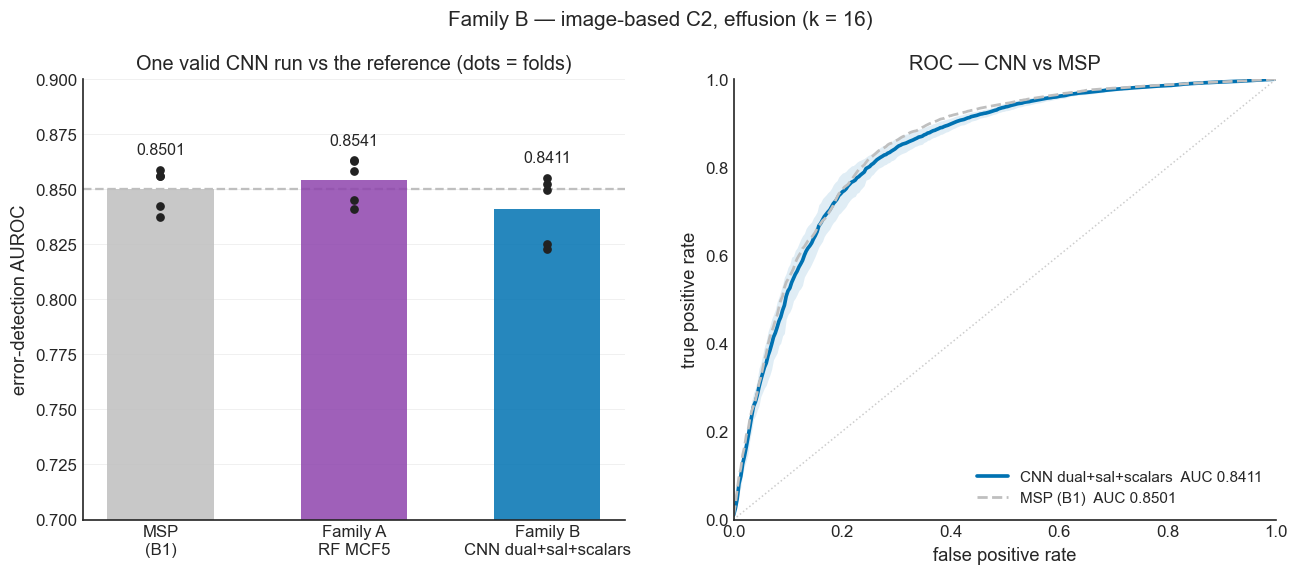

In [ ]:
# ── Fig 5 — the one CNN point in context, and its ROC ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Left: per-fold points so the single run does not read as more precise than it is.
entries = [
    ('MSP\n(B1)', B1_BEST,
     attrA[1]['detailed'][B1_BEST_MODEL]['B1'], PLOT_COLORS['B1']),
    (f'Family A\n{famA_best_mod} {famA_best_cfg}', famA_best_auc,
     attrA[16]['detailed'][famA_best_mod][famA_best_cfg], PLOT_COLORS[famA_best_cfg]),
    ('Family B\nCNN dual+sal+scalars', cnn_auc, cnn_det, '#0072B2'),
]
for i, (lab, mean_auc, folds, colr) in enumerate(entries):
    fold_aucs = [f['auc'] for f in folds]
    axes[0].bar(i, mean_auc, color=colr, width=0.55, alpha=0.85, zorder=2)
    axes[0].scatter([i] * len(fold_aucs), fold_aucs, color='#222222', s=22, zorder=3)
    axes[0].text(i, max(fold_aucs) + 0.007, f'{mean_auc:.4f}', ha='center',
                 fontsize=10.5)

axes[0].axhline(B1_BEST, color=PLOT_COLORS['B1'], ls=PLOT_LS['B1'], lw=1.5, zorder=1)
axes[0].set(xticks=range(len(entries)),
            xticklabels=[e[0] for e in entries],
            ylabel='error-detection AUROC', ylim=(0.70, 0.90),
            title='One valid CNN run vs the reference (dots = folds)')
axes[0].grid(axis='y', alpha=0.3)

axes[1].plot(cnn_summ['fpr'], cnn_summ['tpr'], color='#0072B2', lw=2.4,
             label=f'CNN dual+sal+scalars  AUC {cnn_summ["auc"]:.4f}')
axes[1].fill_between(cnn_summ['fpr'], cnn_summ['tpr'] - cnn_summ['std'],
                     cnn_summ['tpr'] + cnn_summ['std'], color='#0072B2', alpha=0.12, lw=0)
_b1s = summarise(attrA[1]['detailed'][B1_BEST_MODEL]['B1'])
axes[1].plot(_b1s['fpr'], _b1s['tpr'], color=PLOT_COLORS['B1'], ls=PLOT_LS['B1'],
             lw=1.8, label=f'MSP (B1)  AUC {_b1s["auc"]:.4f}')
axes[1].plot([0, 1], [0, 1], color='#CCCCCC', lw=1, ls=':')
axes[1].set(xlabel='false positive rate', ylabel='true positive rate',
            title='ROC — CNN vs MSP', xlim=(0, 1), ylim=(0, 1))
axes[1].legend(frameon=False, loc='lower right')

fig.suptitle(f'Family B — image-based C2, {DISEASE} (k = 16)', y=1.0, fontsize=13.5)
fig.savefig(f'{OUT}/story_famB_cnn_{DISEASE}.png')
plt.show()

In [ ]:
# ── DeLong: CNN vs MSP, aligned by image path ─────────────────────────────────
# The CNN run and the canonical Family-A run share fold assignments (same seed, same
# grouped splitter) but not necessarily row order within a fold, so the two score
# vectors are joined on `path` rather than assumed aligned.
def _fold_scores(run_key, score_col, extra=()):
    frames = []
    for i in range(5):
        f = pd.read_csv(os.path.join(RUNS[run_key], f'fold_{i}_predictions.csv'),
                        usecols=['path', 'correct', score_col, *extra])
        frames.append(f.assign(fold=i))
    return pd.concat(frames, ignore_index=True)


cnn_scores  = _fold_scores('cnnB_k16', 'prob_pred').rename(
    columns={'prob_pred': 'cnn'})
famA_scores = _fold_scores('attrA_k16', f'{B1_BEST_MODEL}_B1_prob').rename(
    columns={f'{B1_BEST_MODEL}_B1_prob': 'msp'})

merged = cnn_scores.merge(famA_scores[['path', 'msp', 'correct']], on='path',
                          suffixes=('', '_a'), validate='one_to_one')
assert (merged['correct'] == merged['correct_a']).all(), 'label mismatch across runs'

a_cnn, a_msp, pv = delong_test(merged['correct'], merged['cnn'], merged['msp'])
print(f'aligned on path, n = {len(merged):,}\n')
print(f'  CNN (dual+sal+scalars, k=16) pooled OOF AUROC : {a_cnn:.4f}')
print(f'  MSP  ({B1_BEST_MODEL} B1)     pooled OOF AUROC : {a_msp:.4f}')
print(f'  delta                                         : {a_cnn - a_msp:+.4f}')
print(f'  DeLong p                                      : '
      f'{"<1e-4" if pv < 1e-4 else f"{pv:.4f}"}')

aligned on path, n = 45,155

  CNN (dual+sal+scalars, k=16) pooled OOF AUROC : 0.8383
  MSP  (MLP B1)     pooled OOF AUROC : 0.8494
  delta                                         : -0.0111
  DeLong p                                      : <1e-4


---
## §6 — Family C: the diffusion-trajectory fingerprint

> *Assumption:* the signal lies not in **where** the counterfactual lands but in the
> **process of getting there**.

Instead of the counterfactual image or its attributes, this family describes how the
guided diffusion trajectory *moved*: velocity, acceleration, monotonicity, backtracking,
re-crossing, steps-to-flip, total variation, polynomial shape terms, and pixel-level
edit statistics — 669 columns after pivoting the (region × t_start) grid wide
(`cf_extract_diverse_features.py` → `cf_fingerprint_cv.py`).

**Scope caveat, repeated deliberately:** this grid covers **5,431 images**, not the 45,155
of §4–§5. The baseline is therefore rebuilt *inside the grid* — `prob_only` is B1
restricted to these images — and no number here should be compared to a number from §4.

In [ ]:
# ── The fingerprint run ───────────────────────────────────────────────────────
traj_sum = load_summary('trajC')
traj_det = load_detailed('trajC')
with open(os.path.join(RUNS['trajC'], 'run_config.json')) as fh:
    traj_cfg = json.load(fh)

SETS = ['prob_only', 'fingerprint', 'both']
SET_LABEL = {'prob_only': 'prob_only  (C0 confidence, in-grid B1)',
             'fingerprint': 'fingerprint  (669 trajectory columns)',
             'both': 'both  (prob + fingerprint)'}
SET_COLOR = {'prob_only': '#0072B2', 'fingerprint': '#D55E00', 'both': '#009E73'}

traj_pivot = (traj_sum.pivot(index='model', columns='feature_set', values='mean_auc')
                      .reindex(columns=SETS).round(4))
traj_pivot['fingerprint − prob_only'] = (traj_pivot['fingerprint']
                                         - traj_pivot['prob_only']).round(4)
traj_pivot['both − prob_only'] = (traj_pivot['both'] - traj_pivot['prob_only']).round(4)

print(f'grid: {traj_cfg["n_images"]:,} images, '
      f'{traj_cfg["n_fingerprint_cols"]} fingerprint columns, '
      f'{traj_cfg["n_folds"]}-fold grouped CV')
print(f'regions: {traj_cfg["regions"]}\n')
traj_pivot

grid: 5,431 images, 669 fingerprint columns, 5-fold grouped CV
regions: ['Facies Diaphragmatica', 'Left Lung', 'Right Lung', 'Spine']



feature_set,prob_only,fingerprint,both,fingerprint − prob_only,both − prob_only
model,,,,,
HGB,0.8058,0.7918,0.7985,-0.0140,-0.0073
LR,0.6253,0.7711,0.7709,0.1458,0.1456
MLP,0.8112,0.7933,0.7953,-0.0179,-0.0159
RF,0.7394,0.8053,0.8073,0.0659,0.0679


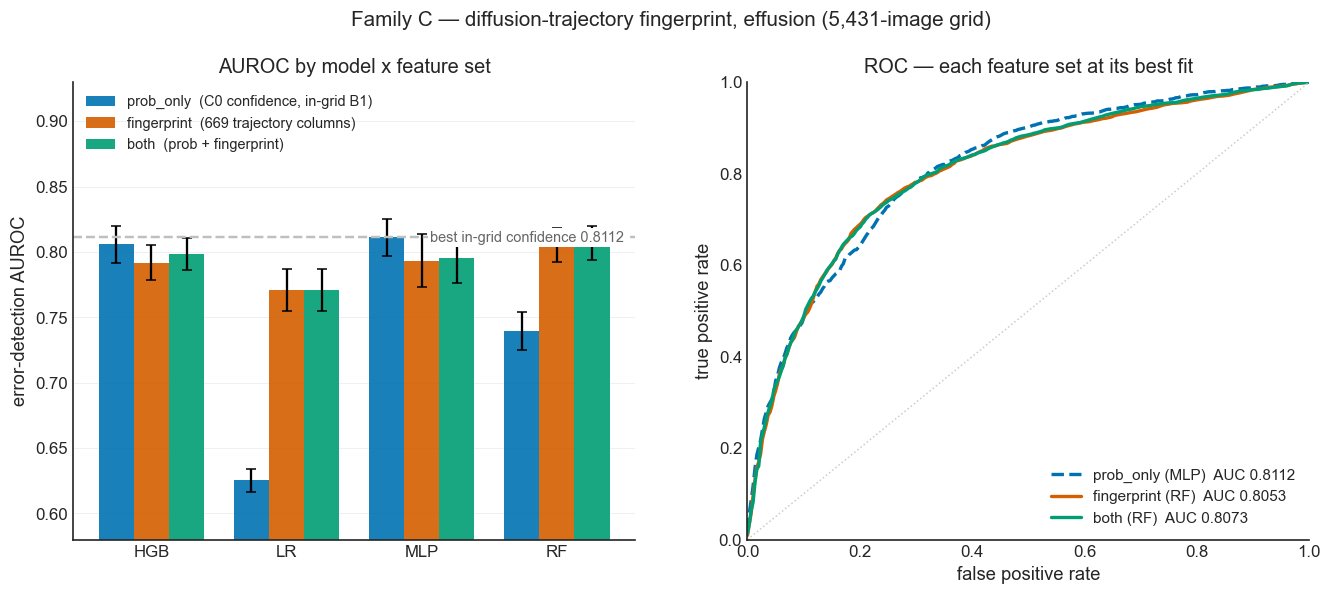

In [ ]:
# ── Fig 6 — fingerprint vs the in-grid confidence baseline ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4))
tmodels = list(traj_pivot.index)
xt = np.arange(len(tmodels))
w = 0.26

for j, fs in enumerate(SETS):
    vals = [traj_sum[(traj_sum.model == m) & (traj_sum.feature_set == fs)]
            ['mean_auc'].iloc[0] for m in tmodels]
    errs = [traj_sum[(traj_sum.model == m) & (traj_sum.feature_set == fs)]
            ['std_auc'].iloc[0] for m in tmodels]
    axes[0].bar(xt + (j - 1) * w, vals, w, yerr=errs, capsize=3,
                color=SET_COLOR[fs], label=SET_LABEL[fs], alpha=0.9)

grid_b1 = float(traj_pivot['prob_only'].max())
axes[0].axhline(grid_b1, color=PLOT_COLORS['B1'], ls=PLOT_LS['B1'], lw=1.6)
axes[0].text(len(xt) - 0.5, grid_b1, f'best in-grid confidence {grid_b1:.4f}',
             ha='right', va='center', fontsize=9.5, color='#666666',
             bbox=dict(fc='white', ec='none', pad=1.5))
axes[0].set(xticks=xt, xticklabels=tmodels, ylabel='error-detection AUROC',
            ylim=(0.58, 0.93), title='AUROC by model x feature set')
axes[0].legend(frameon=False, fontsize=9.5, loc='upper left')
axes[0].grid(axis='y', alpha=0.3)

# Each feature set is shown at its BEST fit across models. Pinning all three to one
# model would compare the fingerprint against that model's own prob_only fit, and RF/LR
# read raw p badly (p is non-monotone in correctness) -- which would flatter the
# fingerprint for a reason that has nothing to do with the trajectory.
for fs in SETS:
    m_best = traj_pivot[fs].idxmax()
    sm = summarise(traj_det[m_best][fs])
    axes[1].plot(sm['fpr'], sm['tpr'], color=SET_COLOR[fs], lw=2.2,
                 ls='--' if fs == 'prob_only' else '-',
                 label=f'{fs} ({m_best})  AUC {sm["auc"]:.4f}')
axes[1].plot([0, 1], [0, 1], color='#CCCCCC', lw=1, ls=':')
axes[1].set(xlabel='false positive rate', ylabel='true positive rate',
            title='ROC — each feature set at its best fit',
            xlim=(0, 1), ylim=(0, 1))
axes[1].legend(frameon=False, loc='lower right')

fig.suptitle(f'Family C — diffusion-trajectory fingerprint, {DISEASE} '
             f'({traj_cfg["n_images"]:,}-image grid)', y=1.0, fontsize=13.5)
fig.savefig(f'{OUT}/story_famC_fingerprint_{DISEASE}.png')
plt.show()

In [ ]:
# ── DeLong inside the grid: does the fingerprint add anything to confidence? ──
rows = []
for m in tmodels:
    y_p, s_p = pooled_oof(traj_det[m]['prob_only'])
    for fs in ['fingerprint', 'both']:
        y_f, s_f = pooled_oof(traj_det[m][fs])
        assert np.array_equal(y_f, y_p), f'{m}/{fs}: OOF labels misaligned'
        a_f, a_p, pv = delong_test(y_p, s_f, s_p)
        rows.append({'model': m, 'feature set': fs,
                     'AUROC': round(a_f, 4), 'prob_only': round(a_p, 4),
                     'delta': round(a_f - a_p, 4),
                     'p (DeLong)': '<1e-4' if pv < 1e-4 else f'{pv:.4f}',
                     'verdict': ('better' if (pv < 0.05 and a_f > a_p)
                                 else 'worse' if (pv < 0.05) else 'n.s.')})

traj_delong = pd.DataFrame(rows)
print(f'each row: feature set vs that model own prob_only fit, same images, '
      f'n = {len(y_p):,}\n')
traj_delong

each row: feature set vs that model own prob_only fit, same images, n = 5,431



,model,feature set,AUROC,prob_only,delta,p (DeLong),verdict
0,HGB,fingerprint,0.7912,0.8040,-0.0129,0.0011,worse
1,HGB,both,0.7978,0.8040,-0.0062,0.0793,n.s.
2,LR,fingerprint,0.7707,0.6252,0.1456,<1e-4,better
3,LR,both,0.7706,0.6252,0.1454,<1e-4,better
4,MLP,fingerprint,0.7918,0.7997,-0.0079,0.0602,n.s.
5,MLP,both,0.7898,0.7997,-0.0098,0.0202,worse
6,RF,fingerprint,0.8043,0.7392,0.0651,<1e-4,better
7,RF,both,0.8064,0.7392,0.0672,<1e-4,better


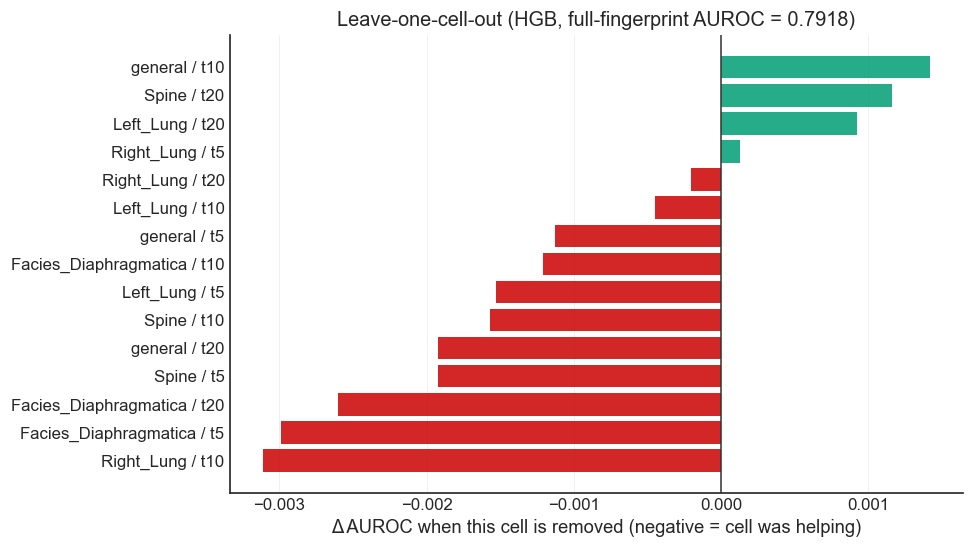

largest absolute effect of removing any single cell: 0.0031 AUROC
For reference, the fold-to-fold SD of the full fingerprint model is 0.0135.


In [ ]:
# ── Cell ablation: is any single (region x t_start) cell load-bearing? ────────
abl = pd.read_csv(SOURCES['cell_abl'])
full_auc = float(abl.loc[abl.cell == 'FULL', 'auc_mean'].iloc[0])
drops = abl[abl.cell != 'FULL'].copy()
drops['cell'] = drops['cell'].str.replace('^__', '', regex=True).str.replace('__', ' / ')
drops = drops.sort_values('delta_vs_full')

fig, ax = plt.subplots(figsize=(8.6, 5.4))
colors = ['#CC0000' if d < 0 else '#009E73' for d in drops['delta_vs_full']]
ax.barh(range(len(drops)), drops['delta_vs_full'], color=colors, alpha=0.85)
ax.axvline(0, color='#333333', lw=1)
ax.set(yticks=range(len(drops)), yticklabels=drops['cell'],
       xlabel='Δ AUROC when this cell is removed (negative = cell was helping)',
       title=f'Leave-one-cell-out (HGB, full-fingerprint AUROC = {full_auc:.4f})')
ax.grid(axis='x', alpha=0.3)
fig.savefig(f'{OUT}/story_famC_cell_ablation_{DISEASE}.png')
plt.show()

print(f'largest absolute effect of removing any single cell: '
      f'{drops["delta_vs_full"].abs().max():.4f} AUROC')
print('For reference, the fold-to-fold SD of the full fingerprint model is '
      f'{float(abl.loc[abl.cell == "FULL", "auc_std"].iloc[0]):.4f}.')

**Reading Family C.** The fingerprint is *not* noise — it reaches ~0.79–0.81 AUROC on its
own, well above chance, so the diffusion trajectory genuinely carries correctness
information. But **it does not beat the C0 probability inside the same grid**, and adding
it to the probability (`both`) does not reliably improve on the probability alone.

The cell ablation says the same thing from a different direction: removing any single
(region × t_start) cell moves AUROC by less than the fold-to-fold SD. There is no
localised "this is where the signal lives" cell — the information is diffuse, and largely
redundant with how confident C0 already was.

---
## §7 — Where the story stands

### The three families, side by side

Read the caveat column before the AUROC column. The three families are **not** evaluated
on the same images or at the same k, so this table is a status summary, not a benchmark.

In [ ]:
# ── The one summary table the thesis needs ────────────────────────────────────
famA_k1_best_cfg = attrA[1]['auc'].drop(index=NO_CF_CONFIGS).max(axis=1).idxmax()
famA_k1_best_mod = attrA[1]['auc'].loc[famA_k1_best_cfg].idxmax()
famA_ctrl_best = attrA[1]['auc'].loc[[c for c in NO_CF_CONFIGS if c != 'B1']].max().max()

overview = pd.DataFrame([
    {'family': 'A — attributes (Δ-attr)',
     'best CF config': f'{famA_k1_best_mod} {famA_k1_best_cfg} (k=1)',
     'AUROC': round(float(attrA[1]['auc'].loc[famA_k1_best_cfg].max()), 4),
     'its own baseline': f'MSP {B1_BEST:.4f}',
     'gain': round(float(attrA[1]['auc'].loc[famA_k1_best_cfg].max()) - B1_BEST, 4),
     'n images': f'{len(c2):,}',
     'caveat': 'best CF-free control (B3/B5) already at '
               f'{famA_ctrl_best:.4f}'},
    {'family': 'B — images (CNN)',
     'best CF config': 'dual+sal+scalars (k=16)',
     'AUROC': round(cnn_auc, 4),
     'its own baseline': f'MSP {B1_BEST:.4f}',
     'gain': round(cnn_auc - B1_BEST, 4),
     'n images': f'{len(c2):,}',
     'caveat': 'ONE run; no channel ablation, no k=1'},
    {'family': 'C — diffusion trajectory',
     'best CF config': f'fingerprint ({traj_pivot["fingerprint"].idxmax()})',
     'AUROC': round(float(traj_pivot['fingerprint'].max()), 4),
     'its own baseline': f'in-grid prob {grid_b1:.4f}',
     'gain': round(float(traj_pivot['fingerprint'].max()) - grid_b1, 4),
     'n images': f'{traj_cfg["n_images"]:,}',
     'caveat': 'different, smaller evaluation set'},
])
overview

,family,best CF config,AUROC,its own baseline,gain,n images,caveat
0,A — attributes (Δ-attr),MLP MCF1 (k=1),0.8530,MSP 0.8501,0.0029,"45,155",best CF-free control (B3/B5) already at 0.8487
1,B — images (CNN),dual+sal+scalars (k=16),0.8411,MSP 0.8501,-0.0090,"45,155","ONE run; no channel ablation, no k=1"
2,C — diffusion trajectory,fingerprint (RF),0.8053,in-grid prob 0.8112,-0.0059,"5,431","different, smaller evaluation set"


### What this says for the three Aims

**Aim 1 — is there a correctness signal in the counterfactual process, and where?**
Yes, in all three families: Δ-attributes, the input/CF image pair, and the diffusion
trajectory all score well above chance. But in every family the signal is *largely
redundant with C0's own confidence*, and in Family A the embedding-only controls (`B3`,
`B5`) — which involve no counterfactual at all — capture most of it.

**Aim 2 — does it outperform the MSP baseline?**
On the evidence currently on disk: **not by a margin that survives an honest comparator.**
The counterfactual-attributable gain in Family A is a few thousandths of AUROC over the
best CF-free control. Family C loses to confidence inside its own grid. Family B cannot
be assessed — its ablation has no post-leak-fix data.

**Aim 3 — explanation and transfer.**
Both sub-questions currently rest on pre-fix runs (gap rows 10–11) and on two of the three
planned CheXpert tasks (cardiomegaly has no C2 run of any kind).

This is a coherent and defensible thesis result — it is exactly the position the proposal's
*Impact* section stakes out: retrieval-based counterfactuals are structurally tied to the
margin the softmax already encodes, and the contribution is to establish *where to look*
rather than to claim a win. What it needs is the missing runs below so the negative result
is stated over a complete ablation rather than a partial one.

In [ ]:
# ── The gap table ─────────────────────────────────────────────────────────────
GAPS = [
    (1, 'A', 'Attributes x NN-CF, effusion, k=1 & 16, full B1-B5 ladder',
     'HAVE', '', ''),
    (2, 'C', 'Trajectory fingerprint CV, effusion (5,431-image grid)',
     'HAVE', '', ''),
    (3, 'C', 'Leave-one-cell-out ablation (region x t_start)',
     'HAVE', '', ''),
    (4, 'B', 'CNN channel ablation xi / xi_sal / cf / cf_sal / dual / dual_sal, '
             'effusion k=1',
     'MISSING', 'pre-leak-fix runs only; blocks the Aim-2 image ablation',
     'code/CNN_baselines/c2_cnn_all.py --disease effusion --cf_count 1 '
     '--models xi xi_sal cf cf_sal dual dual_sal   '
     '(adapt jobs/cnn/run_cnn_dual_sal_scalars_effusion_cf16.sh)'),
    (5, 'B', 'CNN dual_sal_scalars, effusion, k=1',
     'MISSING', 'only k=16 exists, so no k comparison for the image family',
     'same job with --cf_count 1 --models dual_sal_scalars'),
    (6, 'A', 'Attributes x DIFFUSION-CF, effusion',
     'GAP (declared open)',
     'clean pipeline has never produced output; inputs are ready on disk',
     'code/c2/c2_cv_pipeline_diverse_cf.py --disease effusion'),
    (7, 'A', 'Attributes x NN-CF, cardiomegaly',
     'MISSING', 'only c2_data.csv exists; Aim 3 transfer rests on 2 of 3 tasks',
     'code/c2/c2_cv_pipeline_cf_ensemble.py --disease cardiomegaly --cf_count 1 '
     '--entropy'),
    (8, 'B', 'CNN family, pneumothorax, k=1',
     'MISSING', 'only dual_sal_scalars k=16 exists',
     'code/CNN_baselines/c2_cnn_all.py --disease pneumothorax --cf_count 1'),
    (9, 'C', 'Trajectory fingerprint, pneumothorax / RSNA',
     'MISSING', 'only region-calibration CSVs on disk; CFs not generated',
     'jobs/cf_generation/diverse_cf_run_{pneumothorax,rsna}.sh -> '
     'cf_extract_diverse_features.py -> cf_fingerprint_cv.py'),
    (10, 'A', 'Subgroup + confidence-band stratification (Aim 3)',
     'STALE', 'computed against the superseded TEST_entropy run',
     're-point notebooks/ROC_tabular.ipynb section 8 at the canonical run'),
    (11, 'A', 'Delta-attribute explainability per TP/TN/FP/FN quadrant (Aim 3)',
     'STALE', 'pre-leak-fix folds',
     'code/c2/c2_feature_importance_new_split.py on the canonical folds'),
]

gaps = pd.DataFrame(GAPS, columns=['#', 'family', 'experiment', 'status',
                                   'why it matters', 'how to run'])
gaps.to_csv(f'{OUT}/experiment_status.csv', index=False)

print(gaps['status'].value_counts().to_string())
print(f'\nwritten -> {OUT}/experiment_status.csv')
with pd.option_context('display.max_colwidth', 90):
    display(gaps[['#', 'family', 'experiment', 'status']])

status
MISSING                5
HAVE                   3
STALE                  2
GAP (declared open)    1

written -> /zhome/d0/a/221493/thesis/notebooks/images/experiment_status.csv


,#,family,experiment,status
0,1,A,"Attributes x NN-CF, effusion, k=1 & 16, full B1-B5 ladder",HAVE
1,2,C,"Trajectory fingerprint CV, effusion (5,431-image grid)",HAVE
2,3,C,Leave-one-cell-out ablation (region x t_start),HAVE
3,4,B,"CNN channel ablation xi / xi_sal / cf / cf_sal / dual / dual_sal, effusion k=1",MISSING
4,5,B,"CNN dual_sal_scalars, effusion, k=1",MISSING
5,6,A,"Attributes x DIFFUSION-CF, effusion",GAP (declared open)
6,7,A,"Attributes x NN-CF, cardiomegaly",MISSING
7,8,B,"CNN family, pneumothorax, k=1",MISSING
8,9,C,"Trajectory fingerprint, pneumothorax / RSNA",MISSING
9,10,A,Subgroup + confidence-band stratification (Aim 3),STALE


In [ ]:
# ── The same table with the runnable commands, for copy-paste ─────────────────
with pd.option_context('display.max_colwidth', 250):
    display(gaps[gaps.status != 'HAVE'][['#', 'experiment', 'status', 'how to run']]
            .set_index('#'))

,experiment,status,how to run
#,,,
4,"CNN channel ablation xi / xi_sal / cf / cf_sal / dual / dual_sal, effusion k=1",MISSING,code/CNN_baselines/c2_cnn_all.py --disease effusion --cf_count 1 --models xi xi_sal cf cf_sal dual dual_sal (adapt jobs/cnn/run_cnn_dual_sal_scalars_effusion_cf16.sh)
5,"CNN dual_sal_scalars, effusion, k=1",MISSING,same job with --cf_count 1 --models dual_sal_scalars
6,"Attributes x DIFFUSION-CF, effusion",GAP (declared open),code/c2/c2_cv_pipeline_diverse_cf.py --disease effusion
7,"Attributes x NN-CF, cardiomegaly",MISSING,code/c2/c2_cv_pipeline_cf_ensemble.py --disease cardiomegaly --cf_count 1 --entropy
8,"CNN family, pneumothorax, k=1",MISSING,code/CNN_baselines/c2_cnn_all.py --disease pneumothorax --cf_count 1
9,"Trajectory fingerprint, pneumothorax / RSNA",MISSING,"jobs/cf_generation/diverse_cf_run_{pneumothorax,rsna}.sh -> cf_extract_diverse_features.py -> cf_fingerprint_cv.py"
10,Subgroup + confidence-band stratification (Aim 3),STALE,re-point notebooks/ROC_tabular.ipynb section 8 at the canonical run
11,Delta-attribute explainability per TP/TN/FP/FN quadrant (Aim 3),STALE,code/c2/c2_feature_importance_new_split.py on the canonical folds


---
## §8 — Appendix: the same ladder on the other tasks

Kept out of the main narrative because the story above is deliberately effusion-only. This
is the evidence available for the transfer question in Aim 3.

`cardiomegaly` is absent: it has a `c2_data.csv` but no C2 cross-validation run of any
kind (gap row 7).

In [ ]:
# ── Cross-task Family-A summary, where post-fix runs exist ────────────────────
def attr_path(disease, k):
    return (f'{RESULTS}/C2_custom_corrected/{disease}/cv_results_cf_ensemble/'
            f'cf_{k}/distance_l1/strategy_correct_cf/TEST_entropy_added(M-only)')


cross = []
for dis in ['effusion', 'pneumothorax', 'cardiomegaly', 'rsna_pneumonia']:
    for k in (1, 16):
        p = os.path.join(attr_path(dis, k), 'cv_summary.csv')
        if not os.path.exists(p):
            cross.append({'task': dis, 'k': k, 'status': 'no post-fix run'})
            continue
        s = pd.read_csv(p)
        piv = s.pivot(index='config', columns='model', values='mean_auc')
        b1 = float(piv.loc['B1'].max())
        cf_rows = [c for c in piv.index if c not in NO_CF_CONFIGS]
        ctrl_rows = [c for c in piv.index if c in NO_CF_CONFIGS and c != 'B1']
        best_cf = piv.loc[cf_rows].max().max()
        best_ctrl = piv.loc[ctrl_rows].max().max() if ctrl_rows else np.nan
        cross.append({
            'task': dis, 'k': k, 'status': 'ok',
            'MSP (best B1)': round(b1, 4),
            'best CF-free control': round(float(best_ctrl), 4),
            'best CF config': round(float(best_cf), 4),
            'CF gain vs MSP': round(float(best_cf) - b1, 4),
            'CF gain vs control': round(float(best_cf - best_ctrl), 4),
        })

cross_df = pd.DataFrame(cross)
print('"CF gain vs control" is the honest quantity: the control already has prob + emb.\n')
cross_df

"CF gain vs control" is the honest quantity: the control already has prob + emb.



,task,k,status,MSP (best B1),best CF-free control,best CF config,CF gain vs MSP,CF gain vs control
0,effusion,1,ok,0.8501,0.8487,0.8530,0.0029,0.0043
1,effusion,16,ok,0.8501,0.8487,0.8541,0.0040,0.0055
2,pneumothorax,1,ok,0.7871,0.7794,0.7882,0.0010,0.0087
3,pneumothorax,16,ok,0.7871,0.7794,0.7924,0.0052,0.0130
4,cardiomegaly,1,no post-fix run,NaN,NaN,NaN,NaN,NaN
5,cardiomegaly,16,no post-fix run,NaN,NaN,NaN,NaN,NaN
6,rsna_pneumonia,1,ok,0.7204,0.7188,0.7329,0.0124,0.0140
7,rsna_pneumonia,16,ok,0.7204,0.7188,0.7334,0.0130,0.0145


The pattern replicates: on every task with a post-fix run, the best counterfactual config
sits within a few thousandths of the best counterfactual-**free** control. Whatever the
retrieval-based counterfactual adds, it adds it on top of information the classifier's own
probability and embedding already contain — which is precisely the redundancy the
proposal's *Future work* section predicts for nearest-opposite-neighbour retrieval.